# Multi-cell-line PDAC drug-combination modelling

Grouped classical and neural model comparisons, training-fold propensity baselines, focused nested hyperparameter sensitivity and identity-free cold-drug validation, corresponding to thesis Sections 2.3.1–2.3.7 and Results 3.2.1–3.2.3.

**Inputs:** the canonical 8,450-unit PDAC multi-cell-line table with Morgan fingerprints, and the DepMap PDAC gene-expression matrix for train-only PCA. Both inputs can be CSV or pickle. Input datasets are read locally. Figure-generation cells may write derived results under the Git-ignored `results/` directory. Candidate ranking and external PDAC validation are intentionally excluded. Run from a clean kernel and examine the actual computed results; they are not prefilled with manuscript values.

## Python packages and settings

In [1]:
from pathlib import Path
import copy
import json
import time
import matplotlib.pyplot as plt
import itertools
import math
import random
import re

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (AdaBoostClassifier, BaggingClassifier,
                              ExtraTreesClassifier, GradientBoostingClassifier,
                              HistGradientBoostingClassifier, RandomForestClassifier)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit, ParameterSampler
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
N_SPLITS = 10
TEST_FRACTION = 0.20
N_PCS = 20
MIN_GENE_SD = 0.05
ENDPOINTS = ('any_positive_label', 'majority_label')
VALIDATIONS = {'unseen_cell_line': 'ModelID', 'unseen_drug_pair': 'drug_pair_group'}
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
print('PyTorch device:', DEVICE)

PyTorch device: cpu


## Input datasets

In [ ]:
# Find the repository root when running from the root or notebooks folder.
REPO_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "notebooks" / "multi_cell_line_grouped_validation.ipynb").is_file()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError("Run this notebook from within the thesis repository.")

UNIT_TABLE_PATH = REPO_ROOT / "tables" / "pdac_multicell_drug_pair_units_with_morgan.csv"
DEPMAP_EXPRESSION_PATH = REPO_ROOT / "tables" / "depmap_pdac_full_expression_for_fold_pca.csv"

missing = [p for p in (UNIT_TABLE_PATH, DEPMAP_EXPRESSION_PATH) if not p.is_file()]
if missing:
    raise FileNotFoundError(
        "Required local input files are missing: "
        + ", ".join(map(str, missing))
        + ". These source-derived files are not redistributed on GitHub."
    )

unit_path = Path(UNIT_TABLE_PATH).expanduser().resolve()
expression_path = Path(DEPMAP_EXPRESSION_PATH).expanduser().resolve()
if unit_path == expression_path:
    raise ValueError('Unit-level and expression inputs must be different files.')

def load_table(path):
    if not path.is_file():
        raise FileNotFoundError(path)
    if path.suffix.lower() == '.pkl':
        return pd.read_pickle(path)
    if path.suffix.lower() == '.csv':
        return pd.read_csv(path, low_memory=False)
    raise ValueError('The input must be a .csv or .pkl file.')

units = load_table(unit_path).reset_index(drop=True).copy()
expression_raw = load_table(expression_path).copy()
if 'ModelID' not in expression_raw.columns and expression_raw.index.name == 'ModelID':
    expression_raw = expression_raw.reset_index()

required = {'ModelID', 'positive_fraction', 'drug_a_norm', 'drug_b_norm'}
if not required.issubset(units.columns):
    raise KeyError(f'Missing unit columns: {sorted(required - set(units.columns))}')
units['ModelID'] = units['ModelID'].astype(str)
units['positive_fraction'] = pd.to_numeric(units['positive_fraction'], errors='raise')
if units['positive_fraction'].isna().any() or not units['positive_fraction'].between(0,1).all():
    raise ValueError('positive_fraction contains invalid values.')
units['any_positive_label'] = (units['positive_fraction'] > 0).astype(np.int8)
units['majority_label'] = (units['positive_fraction'] > 0.5).astype(np.int8)
units['drug_a_norm'] = units['drug_a_norm'].astype(str).str.strip().str.upper()
units['drug_b_norm'] = units['drug_b_norm'].astype(str).str.strip().str.upper()
units['drug_pair_group'] = ['||'.join(sorted((a,b))) for a,b in
                            zip(units['drug_a_norm'],units['drug_b_norm'])]

assert len(units) == 8450
assert units['ModelID'].nunique() == 26
assert units['drug_pair_group'].nunique() == 325
assert not units.duplicated(['ModelID','drug_pair_group']).any()
assert units['any_positive_label'].sum() == 1063
assert units['majority_label'].sum() == 188
assert units.groupby('drug_pair_group')['ModelID'].nunique().eq(26).all()

display(pd.DataFrame({'endpoint': ENDPOINTS,
    'positive': [int(units[c].sum()) for c in ENDPOINTS],
    'prevalence': [float(units[c].mean()) for c in ENDPOINTS]}))


,endpoint,positive,prevalence
0,any_positive_label,1063,0.125799
1,majority_label,188,0.022249


## Molecular features

In [3]:
def numbered_cols(prefix):
    cols = [c for c in units if re.fullmatch(rf'{re.escape(prefix)}\d+', str(c))]
    return sorted(cols, key=lambda c: int(c.rsplit('_', 1)[-1]))

A_COLS = numbered_cols('drug_a_fp_')
B_COLS = numbered_cols('drug_b_fp_')
PC_COLS = numbered_cols('expr_pca_')[:N_PCS]
if len(A_COLS) != 512 or len(B_COLS) != 512 or len(PC_COLS) != 20:
    raise ValueError('Expected 512 Morgan bits per drug and 20 stored expression PCs.')

fp_a = units[A_COLS].to_numpy(dtype=np.float32)
fp_b = units[B_COLS].to_numpy(dtype=np.float32)
if not np.isfinite(fp_a).all() or not np.isfinite(fp_b).all():
    raise ValueError('Missing or non-finite Morgan fingerprint features.')

fp_mean = (fp_a + fp_b) / 2
fp_absdiff = np.abs(fp_a - fp_b)
MORGAN_COLS = [f'sym_morgan_mean_{i:04d}' for i in range(512)] + [
    f'sym_morgan_absdiff_{i:04d}' for i in range(512)]
morgan_features = pd.DataFrame(np.hstack([fp_mean, fp_absdiff]), columns=MORGAN_COLS)

ANNOTATION_PAIRS = (
    ('drug_a_target', 'drug_b_target', 'target_pair_symmetric'),
    ('drug_a_pathway', 'drug_b_pathway', 'pathway_pair_symmetric'),
    ('drug_a_drug_type', 'drug_b_drug_type', 'drug_type_pair_symmetric'),
    ('drug_a_drugcomb_target_name_raw', 'drug_b_drugcomb_target_name_raw', 'drugcomb_target_name_pair_symmetric'),
    ('drug_a_drugcomb_target_type_raw', 'drug_b_drugcomb_target_type_raw', 'drugcomb_target_type_pair_symmetric'),
)
ANN_COLS = []
for a, b, out in ANNOTATION_PAIRS:
    if a not in units or b not in units:
        raise KeyError(f'Annotation columns not found: {a}, {b}')
    units[out] = [' || '.join(sorted((str(x), str(y)))) for x, y in
                  zip(units[a].fillna('missing'), units[b].fillna('missing'))]
    ANN_COLS.append(out)

FEATURE_COLS = ANN_COLS + MORGAN_COLS + PC_COLS
assert len(FEATURE_COLS) == 1049
print('Symmetric annotations:', len(ANN_COLS), '| Morgan features:', len(MORGAN_COLS),
      '| expression PCs:', len(PC_COLS))

Symmetric annotations: 5 | Morgan features: 1024 | expression PCs: 20


## Gene-expression PCA

In [4]:
if 'ModelID' not in expression_raw.columns:
    raise KeyError('The DepMap expression matrix must have a ModelID column or index.')

expression_raw['ModelID'] = expression_raw['ModelID'].astype(str)
flag_cols = [c for c in expression_raw.columns if str(c).lower() in
             {'is_default_entry', 'isdefaultentryformodel','is_default_entry_for_model'}]
if flag_cols:
    default = expression_raw[flag_cols[0]].astype(str).str.lower().isin(('true','1','yes'))
    if default.any():
        expression_raw = expression_raw.loc[default].copy()
expression_raw = expression_raw.loc[expression_raw['ModelID'].isin(units['ModelID'])].copy()
metadata = {'profileid','modelconditionid','is_default_entry','isdefaultentryformodel',
            'is_default_entry_for_model','sequencingid','source'}
expression = expression_raw.drop(
    columns=[c for c in expression_raw.columns if str(c).lower() in metadata],
    errors='ignore').set_index('ModelID')
expression = expression.apply(pd.to_numeric,errors='coerce')
expression = expression.replace([np.inf,-np.inf],np.nan).dropna(axis=1,how='all')
expression.columns = [str(c).strip().split(' ')[0].split('(')[0].upper()
                      for c in expression.columns]
expression = expression.loc[:,[bool(c) for c in expression.columns]]
expression = expression.T.groupby(level=0,sort=True).mean().T
expression = expression.groupby(level=0,sort=True).mean()
if not set(units['ModelID']).issubset(expression.index):
    raise ValueError('DepMap expression lacks some of the 26 modelling cell lines.')
expression = expression.loc[sorted(units['ModelID'].unique())]
if expression.shape != (26,19215):
    raise ValueError(f'DepMap gene-expression dimensions must be 26 x 19215; got {expression.shape}. '
                     'Confirm DEPMAP_EXPRESSION_PATH points to the genuine expression table.')
if expression.columns.isin(units.columns).sum() > 10:
    raise ValueError('Expression columns unexpectedly overlap the unit table.')
print('Verified DepMap expression:',expression.shape)

_pca_cache = {}
def fit_expression_pca(training_model_ids):
    train_ids = tuple(dict.fromkeys(map(str,training_model_ids)))
    if train_ids in _pca_cache:
        return _pca_cache[train_ids]
    genes = expression.loc[list(train_ids)].astype(np.float64)
    medians = genes.median(axis=0)
    genes = genes.loc[:,genes.notna().any(axis=0)]
    medians = medians.loc[genes.columns]
    genes = genes.fillna(medians)
    sd = genes.std(axis=0,ddof=0).to_numpy(dtype=np.float64,na_value=np.nan)
    keep = np.isfinite(sd) & (sd >= MIN_GENE_SD)
    genes = genes.iloc[:,keep]
    medians = medians.loc[genes.columns]
    if len(train_ids)<2 or genes.shape[1]<2:
        raise ValueError('Insufficient training cell lines or variable genes for PCA.')
    values = genes.to_numpy(dtype=np.float64)
    scaler = StandardScaler().fit(values)
    n_components = min(N_PCS,len(train_ids)-1,values.shape[1])
    pca = PCA(n_components=n_components,svd_solver='full').fit(scaler.transform(values))
    fitted = (list(genes.columns),medians,scaler,pca)
    _pca_cache[train_ids] = fitted
    return fitted

def transform_expression_pca(model_ids,fitted):
    columns,medians,scaler,pca = fitted
    ids = pd.Series(model_ids).astype(str)
    unique_ids = pd.Index(ids.unique())
    genes = expression.loc[unique_ids,columns].fillna(medians)
    scores = pca.transform(scaler.transform(genes.to_numpy(dtype=np.float64)))
    if scores.shape[1]<N_PCS:
        scores = np.pad(scores,((0,0),(0,N_PCS-scores.shape[1])))
    transformed = pd.DataFrame(scores,index=unique_ids,columns=PC_COLS)
    return transformed.loc[ids.to_numpy()].to_numpy(dtype=np.float32)

def make_fold_features(train_idx,test_idx,validation):
    train = units.iloc[train_idx].copy()
    test = units.iloc[test_idx].copy()
    if validation == 'unseen_cell_line':
        train_ids = train['ModelID'].unique()
        assert set(train_ids).isdisjoint(test['ModelID'].unique())
        fitted = fit_expression_pca(train_ids)
        train.loc[:,PC_COLS] = transform_expression_pca(train['ModelID'],fitted)
        test.loc[:,PC_COLS] = transform_expression_pca(test['ModelID'],fitted)
    return train,test


Verified DepMap expression: (26, 19216)


## Grouped validation splits

In [5]:
SPLITS = {}
for validation, group_col in VALIDATIONS.items():
    groups = units[group_col].astype(str)
    split_generator = GroupShuffleSplit(n_splits=N_SPLITS, test_size=TEST_FRACTION,
                                        random_state=SEED)
    SPLITS[validation] = list(split_generator.split(units, groups=groups))
    for tr, te in SPLITS[validation]:
        assert set(groups.iloc[tr]).isdisjoint(set(groups.iloc[te]))

split_audit = pd.DataFrame([
    {'validation': validation, 'split': i, 'n_train': len(tr), 'n_test': len(te),
     'train_groups': units.iloc[tr][VALIDATIONS[validation]].nunique(),
     'test_groups': units.iloc[te][VALIDATIONS[validation]].nunique(),
     'any_test_prevalence': units.iloc[te]['any_positive_label'].mean(),
     'majority_test_prevalence': units.iloc[te]['majority_label'].mean()}
    for validation, folds in SPLITS.items()
    for i, (tr, te) in enumerate(folds, 1)
])
display(split_audit.groupby('validation').agg({'n_train':'mean','n_test':'mean',
                                               'train_groups':'mean','test_groups':'mean'}))

,n_train,n_test,train_groups,test_groups
validation,,,,
unseen_cell_line,6500.0,1950.0,20.0,6.0
unseen_drug_pair,6760.0,1690.0,260.0,65.0


## Classical models and hyperparameters

In [6]:
def onehot():
    try:
        return OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown='ignore', sparse=False)

def bagging():
    tree = DecisionTreeClassifier(min_samples_leaf=2, random_state=SEED)
    try:
        return BaggingClassifier(estimator=tree, n_estimators=200, max_samples=0.8,
                                 max_features=0.8, n_jobs=-1, random_state=SEED)
    except TypeError:
        return BaggingClassifier(base_estimator=tree, n_estimators=200, max_samples=0.8,
                                 max_features=0.8, n_jobs=-1, random_state=SEED)

def adaboost():
    tree = DecisionTreeClassifier(max_depth=2, min_samples_leaf=5, random_state=SEED)
    try:
        return AdaBoostClassifier(estimator=tree, n_estimators=250, learning_rate=0.05,
                                  random_state=SEED)
    except TypeError:
        return AdaBoostClassifier(base_estimator=tree, n_estimators=250, learning_rate=0.05,
                                  random_state=SEED)

def hgb():
    params = dict(max_iter=100, learning_rate=0.08, max_leaf_nodes=31,
                  l2_regularization=0.1, random_state=SEED)
    try:
        return HistGradientBoostingClassifier(class_weight=None, **params)
    except TypeError:
        return HistGradientBoostingClassifier(**params)

CLASSICAL_MODELS = {
    'dummy_prevalence': DummyClassifier(strategy='prior'),
    'logistic_balanced': LogisticRegression(max_iter=3000, solver='lbfgs', random_state=SEED),
    'decision_tree': DecisionTreeClassifier(min_samples_leaf=5, random_state=SEED),
    'random_forest': RandomForestClassifier(n_estimators=500, min_samples_leaf=3,
                                            max_features='sqrt', n_jobs=-1, random_state=SEED),
    'extra_trees': ExtraTreesClassifier(n_estimators=500, min_samples_leaf=3,
                                        max_features='sqrt', n_jobs=-1, random_state=SEED),
    'bagging_tree': bagging(),
    'gradient_boosting_sklearn': GradientBoostingClassifier(n_estimators=250,
        learning_rate=0.05, max_depth=3, random_state=SEED),
    'hist_gradient_boosting': hgb(),
    'adaboost_tree': adaboost(),
    'xgboost_hist': XGBClassifier(n_estimators=500, max_depth=3, learning_rate=0.03,
        subsample=0.85, colsample_bytree=0.85, objective='binary:logistic',
        eval_metric='logloss', tree_method='hist', n_jobs=-1, random_state=SEED),
    'lightgbm_gbdt': LGBMClassifier(n_estimators=500, learning_rate=0.03,
        num_leaves=31, subsample=0.85, colsample_bytree=0.85,
        objective='binary', n_jobs=-1, random_state=SEED, verbose=-1),
    'catboost': CatBoostClassifier(iterations=500, learning_rate=0.03, depth=6,
        loss_function='Logloss', eval_metric='AUC', random_seed=SEED,
        verbose=False, allow_writing_files=False),
}


# Historical model-family feature contract and estimator fitting.
# Inputs required: units, expression, ANN_COLS, PC_COLS, A_COLS, B_COLS,
# MIN_GENE_SD, N_PCS, SEED and the imports from the notebook setup.

# Match the corrected historical fold PCA: complete training genes, SD >= 0.05,
# at most n_training_cell_lines - 1 components.
_pca_cache = {}
def fit_expression_pca(training_model_ids):
    train_ids = tuple(dict.fromkeys(map(str, training_model_ids)))
    if train_ids not in _pca_cache:
        genes = expression.loc[list(train_ids)].astype(np.float64)
        genes = genes.loc[:, genes.notna().all(axis=0)]
        sd = genes.std(axis=0, ddof=0).to_numpy(dtype=float)
        genes = genes.iloc[:, np.isfinite(sd) & (sd >= MIN_GENE_SD)]
        if len(train_ids) < 2 or genes.shape[1] < 2:
            raise ValueError('Too few cells or eligible genes for fold PCA.')
        medians = genes.median(axis=0)
        scaler = StandardScaler().fit(genes.to_numpy())
        n_fit = min(N_PCS, len(train_ids) - 1, genes.shape[1])
        pca = PCA(n_components=n_fit, svd_solver='full').fit(
            scaler.transform(genes.to_numpy()))
        _pca_cache[train_ids] = (list(genes.columns), medians, scaler, pca)
    return _pca_cache[train_ids]

def transform_expression_pca(model_ids, fitted):
    columns, medians, scaler, pca = fitted
    ids = pd.Series(model_ids).astype(str)
    unique_ids = pd.Index(ids.unique())
    values = expression.loc[unique_ids, columns].fillna(medians).to_numpy(dtype=np.float64)
    projected = pca.transform(scaler.transform(values))
    if projected.shape[1] < N_PCS:
        projected = np.pad(projected, ((0, 0), (0, N_PCS - projected.shape[1])))
    return pd.DataFrame(projected, index=unique_ids, columns=PC_COLS).loc[
        ids.to_numpy()].to_numpy(dtype=np.float32)

# Reference scripts created the symmetrical Morgan columns after lexicographically
# sorting the original fp column names, not numerically sorting the bit indices.
_a_legacy = sorted(A_COLS, key=str)
_b_legacy = sorted(B_COLS, key=str)
_a = units[_a_legacy].to_numpy(dtype=np.float32)
_b = units[_b_legacy].to_numpy(dtype=np.float32)
LEGACY_MORGAN_COLS = [f'sym_morgan_mean_{i:04d}' for i in range(512)] + [
    f'sym_morgan_absdiff_{i:04d}' for i in range(512)]
legacy_morgan = pd.DataFrame(np.hstack(((_a + _b) / 2, np.abs(_a - _b))),
                             columns=LEGACY_MORGAN_COLS, index=units.index)
LEGACY_FEATURE_COLS = ANN_COLS + LEGACY_MORGAN_COLS + PC_COLS
assert len(LEGACY_FEATURE_COLS) == 1049

def historical_inputs(frame):
    return pd.concat([frame[ANN_COLS], legacy_morgan.loc[frame.index],
                      frame[PC_COLS]], axis=1).loc[:, LEGACY_FEATURE_COLS]

def historical_preprocessor(train, scale_numeric=False):
    categoricals = ANN_COLS
    numerics = LEGACY_MORGAN_COLS + PC_COLS
    cat_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
        ('onehot', onehot())
    ])
    steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale_numeric:
        steps.append(('scale', StandardScaler()))
    return ColumnTransformer([
        ('categorical', cat_pipeline, categoricals),
        ('numeric', Pipeline(steps), numerics),
    ], remainder='drop', sparse_threshold=0.0,
       verbose_feature_names_out=False)

# Historical training pipeline: balanced sample weights if supported and
# unweighted fallback if a fitted estimator rejects those weights.
def fit_tabular_model(estimator, train, test, endpoint, scale=False):
    x_train = historical_inputs(train)
    x_test = historical_inputs(test)
    y_train = train[endpoint].astype(int)
    pipe = Pipeline([
        ('preprocess', historical_preprocessor(train, scale_numeric=scale)),
        ('model', clone(estimator)),
    ])
    weights = compute_sample_weight(class_weight='balanced', y=y_train)
    try:
        pipe.fit(x_train, y_train, model__sample_weight=weights)
    except Exception as exc:
        # Precisely the historical fallback. An unexpected error should remain
        # visible if the unweighted refit is also unsuccessful.
        print(f'  Model sample-weight fallback: {type(estimator).__name__}: '
              f'{type(exc).__name__}: {str(exc)[:120]}')
        pipe.fit(x_train, y_train)
    if hasattr(pipe, 'predict_proba'):
        try:
            result = pipe.predict_proba(x_test)[:, 1]
        except AttributeError as exc:
            if '__sklearn_tags__' not in str(exc):
                raise
            # Compatibility with older CatBoost + newer scikit-learn. The
            # already-fitted estimator and fitted transformer are unchanged.
            encoded = pipe.named_steps['preprocess'].transform(x_test)
            result = pipe.named_steps['model'].predict_proba(encoded)[:, 1]
        return np.asarray(result, dtype=float)
    raw = np.asarray(pipe.decision_function(x_test), dtype=float)
    return (raw - np.nanmin(raw)) / (np.nanmax(raw) - np.nanmin(raw) + 1e-12)

# Estimator definitions are unchanged from the historical model-family panel.
# onehot(), bagging(), adaboost(), hgb() and CLASSICAL_MODELS below are retained
# from the original compact setup cell.

def metrics(y, scores):
    labels = np.asarray(y, dtype=int)
    if np.unique(labels).size != 2:
        return {'ap': np.nan, 'roc_auc': np.nan}
    return {'ap': float(average_precision_score(labels, scores)),
            'roc_auc': float(roc_auc_score(labels, scores))}

print('Historical 12-family classical definitions and fold PCA ready.')


Historical 12-family classical definitions and fold PCA ready.


## Grouped classical-model comparison

In [7]:
# Historical 16-family classical/baseline comparison (12 per endpoint).
# Requires only the setup/feature/PCA/model-definition cells, never previous ML outputs.
# For a one-fold smoke test set CLASSICAL_MAX_SPLITS = 1, then restore 10.
CLASSICAL_MAX_SPLITS = 10
assert 1 <= CLASSICAL_MAX_SPLITS <= 10

classical_rows = []
for validation in VALIDATIONS:
    for split_id, (train_idx, test_idx) in enumerate(SPLITS[validation][:CLASSICAL_MAX_SPLITS], 1):
        train, test = make_fold_features(train_idx, test_idx, validation)
        for endpoint in ENDPOINTS:
            for name, estimator in CLASSICAL_MODELS.items():
                scores = fit_tabular_model(estimator, train, test, endpoint,
                                           scale=(name == 'logistic_balanced'))
                classical_rows.append({
                    'validation': validation, 'endpoint': endpoint, 'split': split_id,
                    'model': name, 'test_prevalence': test[endpoint].mean(),
                    **metrics(test[endpoint], scores)
                })
        print('Classical:', validation, 'split', split_id, '/', CLASSICAL_MAX_SPLITS, flush=True)

classical_metrics = pd.DataFrame(classical_rows)
assert len(classical_metrics) == CLASSICAL_MAX_SPLITS * len(VALIDATIONS) * len(ENDPOINTS) * len(CLASSICAL_MODELS)
classical_summary = (classical_metrics.groupby(['validation','endpoint','model'], as_index=False)
    .agg(n_splits=('split','nunique'), ap=('ap','mean'), ap_sd=('ap','std'),
         roc_auc=('roc_auc','mean'), roc_auc_sd=('roc_auc','std'))
    .sort_values(['validation','endpoint','ap'], ascending=[True,True,False]))
with pd.option_context('display.max_rows', None):
    display(classical_summary)


Classical: unseen_cell_line split 1 / 10
Classical: unseen_cell_line split 2 / 10
Classical: unseen_cell_line split 3 / 10
Classical: unseen_cell_line split 4 / 10
Classical: unseen_cell_line split 5 / 10
Classical: unseen_cell_line split 6 / 10
Classical: unseen_cell_line split 7 / 10
Classical: unseen_cell_line split 8 / 10
Classical: unseen_cell_line split 9 / 10
Classical: unseen_cell_line split 10 / 10
Classical: unseen_drug_pair split 1 / 10
Classical: unseen_drug_pair split 2 / 10
Classical: unseen_drug_pair split 3 / 10
Classical: unseen_drug_pair split 4 / 10
Classical: unseen_drug_pair split 5 / 10
Classical: unseen_drug_pair split 6 / 10
Classical: unseen_drug_pair split 7 / 10
Classical: unseen_drug_pair split 8 / 10
Classical: unseen_drug_pair split 9 / 10
Classical: unseen_drug_pair split 10 / 10


,validation,endpoint,model,n_splits,ap,ap_sd,roc_auc,roc_auc_sd
10,unseen_cell_line,any_positive_label,random_forest,10,0.537017,0.054730,0.856978,0.010010
5,unseen_cell_line,any_positive_label,extra_trees,10,0.533821,0.054896,0.857070,0.011377
9,unseen_cell_line,any_positive_label,logistic_balanced,10,0.527477,0.047257,0.853802,0.016765
1,unseen_cell_line,any_positive_label,bagging_tree,10,0.526126,0.058092,0.851112,0.013630
7,unseen_cell_line,any_positive_label,hist_gradient_boosting,10,0.524013,0.057953,0.851726,0.017233
8,unseen_cell_line,any_positive_label,lightgbm_gbdt,10,0.522117,0.059591,0.849354,0.013291
2,unseen_cell_line,any_positive_label,catboost,10,0.521314,0.070801,0.856086,0.013396
11,unseen_cell_line,any_positive_label,xgboost_hist,10,0.510850,0.062846,0.850748,0.013109
6,unseen_cell_line,any_positive_label,gradient_boosting_sklearn,10,0.493749,0.055010,0.844516,0.017797
0,unseen_cell_line,any_positive_label,adaboost_tree,10,0.416707,0.055219,0.815304,0.017699


## Training-fold propensity baselines

In [8]:
SHRINKAGE = {'pair': 5, 'cell': 20, 'drug': 10}

def propensity_predictions(train, test, endpoint, shrinkage=SHRINKAGE):
    g = float(train[endpoint].mean())
    def group_rate(column, lam):
        stats = train.groupby(column)[endpoint].agg(['sum','count'])
        rate = (stats['sum'] + lam * g) / (stats['count'] + lam)
        return test[column].map(rate).fillna(g).to_numpy(dtype=float)
    pair = group_rate('drug_pair_group', shrinkage['pair'])
    cell = group_rate('ModelID', shrinkage['cell'])
    drug_long = pd.concat([
        train[['drug_a_norm',endpoint]].rename(columns={'drug_a_norm':'drug'}),
        train[['drug_b_norm',endpoint]].rename(columns={'drug_b_norm':'drug'})],
        ignore_index=True)
    drug_stats = drug_long.groupby('drug')[endpoint].agg(['sum','count'])
    drug_rate = (drug_stats['sum'] + shrinkage['drug'] * g) / (drug_stats['count'] + shrinkage['drug'])
    a = test['drug_a_norm'].map(drug_rate).fillna(g).to_numpy(dtype=float)
    b = test['drug_b_norm'].map(drug_rate).fillna(g).to_numpy(dtype=float)
    drug = (a + b) / 2
    return {'pair':pair, 'cell':cell, 'drug':drug,
            'pair+drug':(pair+drug)/2, 'cell+drug':(cell+drug)/2,
            'pair+cell+drug':(pair+cell+drug)/3}

propensity_rows = []
for validation in VALIDATIONS:
    for split_id, (tr, te) in enumerate(SPLITS[validation], 1):
        train, test = units.iloc[tr], units.iloc[te]
        for endpoint in ENDPOINTS:
            predictions = propensity_predictions(train, test, endpoint)
            for name, scores in predictions.items():
                propensity_rows.append({'validation':validation, 'endpoint':endpoint,
                    'split':split_id, 'model':name, **metrics(test[endpoint], scores)})

propensity_metrics = pd.DataFrame(propensity_rows)
propensity_summary = (propensity_metrics.groupby(['validation','endpoint','model'],as_index=False)
    .agg(ap=('ap','mean'), ap_sd=('ap','std'),roc_auc=('roc_auc','mean'),
         roc_auc_sd=('roc_auc','std')))
display(propensity_summary)

,validation,endpoint,model,ap,ap_sd,roc_auc,roc_auc_sd
0,unseen_cell_line,any_positive_label,cell,0.122462,0.025783,0.500000,0.000000
1,unseen_cell_line,any_positive_label,cell+drug,0.342297,0.041853,0.788786,0.022317
2,unseen_cell_line,any_positive_label,drug,0.342350,0.041831,0.788773,0.022297
3,unseen_cell_line,any_positive_label,pair,0.507739,0.056752,0.854733,0.011042
4,unseen_cell_line,any_positive_label,pair+cell+drug,0.523044,0.054187,0.859011,0.013947
5,unseen_cell_line,any_positive_label,pair+drug,0.523044,0.054188,0.859002,0.013952
6,unseen_cell_line,majority_label,cell,0.021026,0.006182,0.500000,0.000000
7,unseen_cell_line,majority_label,cell+drug,0.139822,0.064121,0.859703,0.058406
8,unseen_cell_line,majority_label,drug,0.139623,0.063032,0.859394,0.058563
9,unseen_cell_line,majority_label,pair,0.228469,0.077829,0.871123,0.027348


## Matched improvement over propensity

In [9]:
BASELINE_BY_VALIDATION = {'unseen_cell_line':'pair+drug',
                           'unseen_drug_pair':'cell+drug'}
reference = propensity_metrics.loc[
    propensity_metrics.apply(lambda r: r['model'] == BASELINE_BY_VALIDATION[r['validation']],axis=1),
    ['validation','endpoint','split','ap','roc_auc']].rename(
        columns={'ap':'propensity_ap','roc_auc':'propensity_roc_auc'})

paired_classical = classical_metrics.merge(reference,
    on=['validation','endpoint','split'],validate='many_to_one')
paired_classical['delta_ap'] = paired_classical['ap'] - paired_classical['propensity_ap']
paired_classical['delta_roc_auc'] = paired_classical['roc_auc'] - paired_classical['propensity_roc_auc']
paired_classical_summary = (paired_classical.groupby(['validation','endpoint','model'],as_index=False)
    .agg(ap=('ap','mean'),propensity_ap=('propensity_ap','mean'),
         delta_ap=('delta_ap','mean'),delta_ap_sd=('delta_ap','std'),
         delta_roc_auc=('delta_roc_auc','mean'))
    .sort_values(['validation','endpoint','ap'],ascending=[True,True,False]))
display(paired_classical_summary)

,validation,endpoint,model,ap,propensity_ap,delta_ap,delta_ap_sd,delta_roc_auc
10,unseen_cell_line,any_positive_label,random_forest,0.537017,0.523044,0.013973,0.017211,-0.002024
5,unseen_cell_line,any_positive_label,extra_trees,0.533821,0.523044,0.010777,0.014163,-0.001932
9,unseen_cell_line,any_positive_label,logistic_balanced,0.527477,0.523044,0.004433,0.018647,-0.005200
1,unseen_cell_line,any_positive_label,bagging_tree,0.526126,0.523044,0.003083,0.020145,-0.007890
7,unseen_cell_line,any_positive_label,hist_gradient_boosting,0.524013,0.523044,0.000969,0.015840,-0.007276
8,unseen_cell_line,any_positive_label,lightgbm_gbdt,0.522117,0.523044,-0.000927,0.015089,-0.009648
2,unseen_cell_line,any_positive_label,catboost,0.521314,0.523044,-0.001730,0.021553,-0.002915
11,unseen_cell_line,any_positive_label,xgboost_hist,0.510850,0.523044,-0.012194,0.013558,-0.008254
6,unseen_cell_line,any_positive_label,gradient_boosting_sklearn,0.493749,0.523044,-0.029295,0.018742,-0.014485
0,unseen_cell_line,any_positive_label,adaboost_tree,0.416707,0.523044,-0.106337,0.034512,-0.043698


## Propensity shrinkage sensitivity

In [10]:
lambda_rows = []
for validation in VALIDATIONS:
    for split_id, (tr, te) in enumerate(SPLITS[validation], 1):
        train, test = units.iloc[tr], units.iloc[te]
        for endpoint in ENDPOINTS:
            for lam_pair, lam_cell, lam_drug in itertools.product([0,5,10,20,50], repeat=3):
                values = propensity_predictions(train,test,endpoint,
                    {'pair':lam_pair,'cell':lam_cell,'drug':lam_drug})
                choice = BASELINE_BY_VALIDATION[validation]
                lambda_rows.append({'validation':validation,'endpoint':endpoint,
                    'split':split_id,'lambda_pair':lam_pair,'lambda_cell':lam_cell,
                    'lambda_drug':lam_drug, **metrics(test[endpoint],values[choice])})

shrinkage_sensitivity = (pd.DataFrame(lambda_rows).groupby(
    ['validation','endpoint','lambda_pair','lambda_cell','lambda_drug'],as_index=False)
    .agg(ap=('ap','mean'),roc_auc=('roc_auc','mean')))
display(shrinkage_sensitivity.groupby(['validation','endpoint']).agg(
    min_ap=('ap','min'),max_ap=('ap','max')).reset_index())

,validation,endpoint,min_ap,max_ap
0,unseen_cell_line,any_positive_label,0.493593,0.525072
1,unseen_cell_line,majority_label,0.244944,0.246580
2,unseen_drug_pair,any_positive_label,0.349614,0.366012
3,unseen_drug_pair,majority_label,0.148436,0.157312


## Propensity-aligned comparison figure

Rebuilt figure data from CURRENT ten-split notebook results: c:\Users\Käyttäjä\Documents\PDAC-drug-combination-ML-MSc-thesis\results\tables\grouped_validation\ml_vs_propensity_canonical.csv


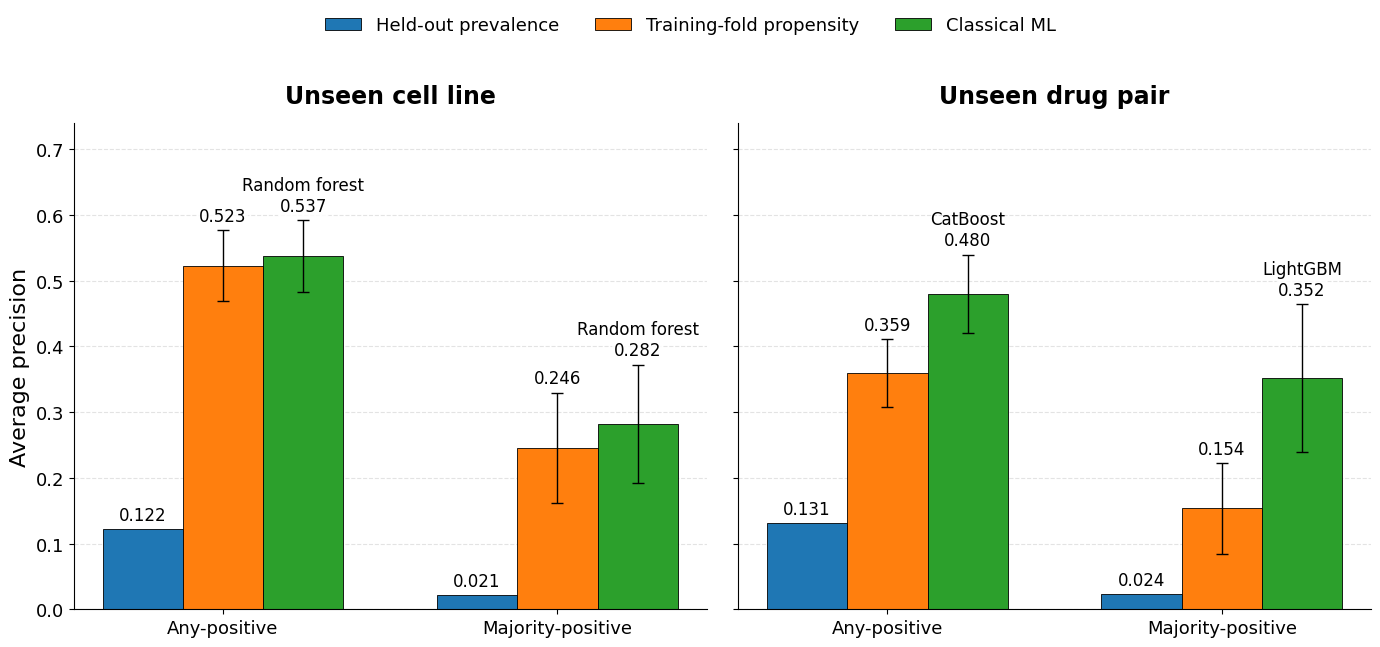

In [ ]:
# ============================================================
# PUBLICATION-STYLE, TWO-PANEL ML VS PROPENSITY FIGURE
#
# Uses the CURRENT grouped-validation run (10 splits).
# When the notebook results exist in memory, rebuilds and saves
# a four-row canonical plot table from the split-level scores.
# After a kernel restart, reads that table instead.
# Does not read the old legacy ml_comprehensive comparison CSV.
# ============================================================

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Fixed choices from the final matched comparison. The baseline must
# correspond to the held-out grouping, not whichever baseline scores best.
TASKS = [
    ("unseen_cell_line", "any_positive_label", "random_forest", "Random forest", "pair+drug"),
    ("unseen_cell_line", "majority_label", "random_forest", "Random forest", "pair+drug"),
    ("unseen_drug_pair", "any_positive_label", "catboost", "CatBoost", "cell+drug"),
    ("unseen_drug_pair", "majority_label", "lightgbm_gbdt", "LightGBM", "cell+drug"),
]

# Locate repository root, whether the notebook is run from root or notebooks/.
ROOT = None
for candidate in (Path.cwd(), *Path.cwd().parents):
    if (candidate / ".git").exists() or (
        candidate / "data/processed/final_github/canonical_order_invariant_unit_with_morgan_github.csv"
    ).is_file():
        ROOT = candidate
        break
if ROOT is None:
    raise FileNotFoundError("Run this notebook inside the thesis GitHub repository.")

TABLE_DIR = ROOT / "results/tables/grouped_validation"
FIGURE_DIR = ROOT / "results/figures/grouped_validation"
TABLE_CSV = TABLE_DIR / "ml_vs_propensity_canonical.csv"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

classical = globals().get("classical_metrics")
propensity = globals().get("propensity_metrics")

if isinstance(classical, pd.DataFrame) and isinstance(propensity, pd.DataFrame):
    required_ml = {"validation", "endpoint", "model", "split", "ap", "test_prevalence"}
    required_prop = {"validation", "endpoint", "model", "split", "ap"}
    if not required_ml.issubset(classical.columns):
        raise ValueError(f"classical_metrics missing: {sorted(required_ml - set(classical.columns))}")
    if not required_prop.issubset(propensity.columns):
        raise ValueError(f"propensity_metrics missing: {sorted(required_prop - set(propensity.columns))}")

    plot_rows = []
    for validation, endpoint, model, label, baseline in TASKS:
        ml = classical.loc[
            (classical["validation"] == validation)
            & (classical["endpoint"] == endpoint)
            & (classical["model"] == model),
            ["split", "ap", "test_prevalence"],
        ].rename(columns={"ap": "ml_ap"})
        prop = propensity.loc[
            (propensity["validation"] == validation)
            & (propensity["endpoint"] == endpoint)
            & (propensity["model"] == baseline),
            ["split", "ap"],
        ].rename(columns={"ap": "propensity_ap"})

        expected_splits = set(range(1, 11))
        if (len(ml) != 10 or len(prop) != 10
                or set(ml["split"]) != expected_splits
                or set(prop["split"]) != expected_splits
                or ml["split"].duplicated().any()
                or prop["split"].duplicated().any()):
            raise ValueError(
                f"Incomplete/mismatched 10-split results for {validation} / {endpoint}. "
                "Finish the grouped classical and propensity evaluations before plotting."
            )
        paired = ml.merge(prop, on="split", validate="one_to_one").sort_values("split")
        if not np.isfinite(paired[["ml_ap", "propensity_ap", "test_prevalence"]]).all().all():
            raise ValueError(f"Non-finite scores for {validation} / {endpoint}")

        plot_rows.append({
            "validation": validation,
            "endpoint": endpoint,
            "model": model,
            "model_label": label,
            "propensity_baseline": baseline,
            "n_splits": 10,
            "test_prevalence_mean": paired["test_prevalence"].mean(),
            "propensity_ap_mean": paired["propensity_ap"].mean(),
            "propensity_ap_sd": paired["propensity_ap"].std(ddof=1),
            "ml_ap_mean": paired["ml_ap"].mean(),
            "ml_ap_sd": paired["ml_ap"].std(ddof=1),
            "paired_delta_ap": (paired["ml_ap"] - paired["propensity_ap"]).mean(),
        })

    figure_data = pd.DataFrame(plot_rows)
    figure_data.to_csv(TABLE_CSV, index=False, float_format="%.12g")
    print("Rebuilt figure data from CURRENT ten-split notebook results:", TABLE_CSV)
else:
    if not TABLE_CSV.is_file():
        raise FileNotFoundError(
            f"No saved plot-data table at {TABLE_CSV}. Run the earlier grouped "
            "classical and propensity evaluation cells once, then rerun this cell. "
            "The canonical raw input CSV cannot provide fitted model AP scores by itself."
        )
    figure_data = pd.read_csv(TABLE_CSV)
    print("Reloaded saved ten-split figure data:", TABLE_CSV)

required = {"validation", "endpoint", "model", "model_label", "propensity_baseline",
            "n_splits", "test_prevalence_mean", "propensity_ap_mean",
            "propensity_ap_sd", "ml_ap_mean", "ml_ap_sd"}
if not required.issubset(figure_data.columns):
    raise ValueError(f"Plot CSV missing columns: {sorted(required - set(figure_data.columns))}")
if len(figure_data) != 4 or figure_data.duplicated(["validation", "endpoint"]).any():
    raise ValueError("Expected exactly one result for each of the four tasks")
for validation, endpoint, model, _, baseline in TASKS:
    selected = figure_data.loc[
        (figure_data.validation == validation) & (figure_data.endpoint == endpoint)
    ]
    if (len(selected) != 1 or selected.iloc[0].model != model
            or selected.iloc[0].propensity_baseline != baseline
            or int(selected.iloc[0].n_splits) != 10):
        raise ValueError(f"Incorrect or incomplete saved result for {validation}/{endpoint}")

plt.rcParams.update({
    "font.size": 13,
    "axes.labelsize": 16,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 13,
})
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), sharey=True)
bar_width = 0.24
panels = [
    ("unseen_cell_line", "Unseen cell line"),
    ("unseen_drug_pair", "Unseen drug pair"),
]
endpoint_names = {"any_positive_label": "Any-positive", "majority_label": "Majority-positive"}

for ax, (validation, title) in zip(axes, panels):
    rows = [figure_data.loc[
        (figure_data.validation == validation) & (figure_data.endpoint == endpoint)
    ].iloc[0] for endpoint in endpoint_names]
    x = np.arange(2)
    prevalence = np.array([float(r.test_prevalence_mean) for r in rows])
    propensity_ap = np.array([float(r.propensity_ap_mean) for r in rows])
    propensity_sd = np.array([float(r.propensity_ap_sd) for r in rows])
    ml_ap = np.array([float(r.ml_ap_mean) for r in rows])
    ml_sd = np.array([float(r.ml_ap_sd) for r in rows])

    bars = [
        (ax.bar(x - bar_width, prevalence, width=bar_width,
                edgecolor="black", linewidth=0.6, label="Held-out prevalence"),
         prevalence, np.zeros(2)),
        (ax.bar(x, propensity_ap, width=bar_width, yerr=propensity_sd,
                error_kw={"capsize": 4, "elinewidth": 1},
                edgecolor="black", linewidth=0.6, label="Training-fold propensity"),
         propensity_ap, propensity_sd),
        (ax.bar(x + bar_width, ml_ap, width=bar_width, yerr=ml_sd,
                error_kw={"capsize": 4, "elinewidth": 1},
                edgecolor="black", linewidth=0.6, label="Classical ML"),
         ml_ap, ml_sd),
    ]

    for bar_group, values, errors in bars:
        for bar, value, err in zip(bar_group, values, errors):
            ax.annotate(
                f"{value:.3f}",
                (bar.get_x() + bar.get_width() / 2, value + err + 0.008),
                ha="center", va="bottom", fontsize=12,
                bbox={"facecolor": "white", "edgecolor": "none",
                      "boxstyle": "round,pad=0.1", "alpha": 0.85},
                zorder=6,
            )

    for bar, row in zip(bars[2][0], rows):
        ax.annotate(
            str(row.model_label),
            (bar.get_x() + bar.get_width() / 2,
             float(row.ml_ap_mean) + float(row.ml_ap_sd) + 0.040),
            ha="center", va="bottom", fontsize=12,
        )

    ax.set_xticks(x, [endpoint_names[r.endpoint] for r in rows])
    ax.set_title(title, fontsize=17, fontweight="bold", pad=14)
    ax.set_ylim(0, 0.74)  # space for AP values and model names above SD bars
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_ylabel("Average precision")
legend_handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(legend_handles, legend_labels, loc="upper center", ncol=3,
           frameon=False, bbox_to_anchor=(0.5, 1.01))
fig.tight_layout(rect=(0, 0, 1, 0.91))

plt.show()

## Neural-network architectures and hyperparameters

In [12]:
# Neural benchmark: a unified five-annotation, checkpoint-retention procedure.
# Same outer grouped folds and input sources as the classical panel.
# All four neural architectures retain the best inner-validation checkpoint.
import random
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = SEED
VALIDATION_SIZE_WITHIN_TRAIN = 0.15
MAX_EPOCHS = 150
PATIENCE = 15
BATCH_SIZE = 256
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT = .20
DRUG_ENCODER_HIDDEN = [256, 64]
PAIR_HEAD_HIDDEN = [128, 64]
device = DEVICE
set_seeds = set_seed
sym_ann_cols = ANN_COLS
ann_cols = ANN_COLS
ann = ANN_COLS

# Identical five symmetric annotation fields across ALL neural architectures
# and both validation settings. No additional clinical annotations are used.
assert len(ANN_COLS) == 5
assert all(column in units.columns for column in ANN_COLS)

pca_cols = PC_COLS
pc_cols = PC_COLS
unit_ids = units['ModelID'].astype(str).reset_index(drop=True)
pair_keys = units['drug_pair_group'].astype(str).reset_index(drop=True)
y_any = units['any_positive_label'].to_numpy(dtype=np.float32)
y_majority = units['majority_label'].to_numpy(dtype=np.float32)
fp_sym = np.hstack((fp_a + fp_b, np.abs(fp_a - fp_b))).astype(np.float32)
NN_MODELS = ('tabular_mlp_bce','tabular_mlp_focal','two_tower_bce')
NN_ENDPOINTS = ('any_positive_label','majority_label')

def make_ohe():
    try:
        return OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown='ignore', sparse=False)

# When cell lines are held out, expression PCA is fitted on the neural
# inner-subtraining cell lines only; unseen-pair uses stored expression PCs.
def fit_fold_expression_pca_encoder(train_model_ids, n_components=N_PCS):
    train_ids = list(dict.fromkeys(map(str, train_model_ids)))
    columns, medians, scaler, pca = fit_expression_pca(train_ids)
    return dict(train_model_ids=train_ids, gene_cols=columns,
                gene_medians=medians, gene_scaler=scaler, pca=pca,
                n_fit_components=pca.n_components_, n_output_components=n_components,
                n_genes=len(columns))

def transform_fold_expression_pca_model_ids(model_ids, encoder):
    ids = list(dict.fromkeys(map(str, model_ids)))
    scores = transform_expression_pca(ids, (
        encoder['gene_cols'], encoder['gene_medians'],
        encoder['gene_scaler'], encoder['pca']))
    return pd.DataFrame(scores, index=ids, columns=PC_COLS)

def transform_fold_expression_pca_indices(indices, encoder):
    ids = units.iloc[np.asarray(indices)]['ModelID'].astype(str)
    df = transform_fold_expression_pca_model_ids(ids.unique(), encoder)
    return df.loc[ids.to_numpy()].to_numpy(dtype=np.float32)


def split_train_validation(
    train_idx,
    groups,
    validation_fraction=VALIDATION_SIZE_WITHIN_TRAIN,
    seed=RANDOM_STATE,
):
    rng = np.random.default_rng(seed)
    train_idx = np.asarray(train_idx)

    group_values = pd.Series(groups).iloc[train_idx].astype(str).to_numpy()
    unique_groups = np.array(sorted(set(group_values)))

    n_val_groups = max(1, int(round(len(unique_groups) * validation_fraction)))
    n_val_groups = min(n_val_groups, max(1, len(unique_groups) - 1))

    val_groups = set(rng.choice(unique_groups, size=n_val_groups, replace=False))
    val_mask = np.array([g in val_groups for g in group_values])
    val_idx = train_idx[val_mask]
    subtrain_idx = train_idx[~val_mask]

    if len(val_idx) == 0 or len(subtrain_idx) == 0:
        raise RuntimeError("Failed to make grouped internal validation split.")

    return subtrain_idx, val_idx

def fit_context_encoder(train_idx, validation_name):
    """Fit all fold-dependent neural preprocessing on the supplied training rows only."""
    train_idx = np.asarray(train_idx)

    if validation_name == "unseen_cell_line":
        train_model_ids = units.iloc[train_idx]["ModelID"].astype(str).unique().tolist()
        expression_encoder = fit_fold_expression_pca_encoder(train_model_ids)
        pca_train = transform_fold_expression_pca_indices(train_idx, expression_encoder)
        pca_mode = "raw_expression_pca_fit_on_training_cell_lines"
        pca_medians = None
    elif validation_name == "unseen_drug_pair":
        expression_encoder = None
        pca_train_df = units.iloc[train_idx][pca_cols].apply(pd.to_numeric, errors="coerce")
        pca_medians = pca_train_df.median(axis=0).fillna(0)
        pca_train = pca_train_df.fillna(pca_medians).to_numpy(dtype=np.float32)
        pca_mode = "stored_internal_expression_pca"
    else:
        raise ValueError(f"Unknown validation_name: {validation_name}")

    # Neural models use standardised PC inputs. This scaler is always fitted on
    # the current neural training subset, irrespective of PCA mode.
    pca_scaler = StandardScaler()
    pca_scaler.fit(pca_train)

    # Never introduce additional annotation fields for a particular setting.
    annotation_cols = list(ANN_COLS)
    assert len(annotation_cols) == 5
    ann_ohe = make_ohe()
    ann_train = units.iloc[train_idx][annotation_cols].fillna("missing").astype(str)
    ann_ohe.fit(ann_train)

    return {
        "validation_name": validation_name,
        "pca_mode": pca_mode,
        "expression_encoder": expression_encoder,
        "pca_medians": pca_medians,
        "pca_scaler": pca_scaler,
        "ann_ohe": ann_ohe,
        "annotation_cols": annotation_cols,
    }

def transform_context(indices, enc):
    indices = np.asarray(indices)

    if enc["validation_name"] == "unseen_cell_line":
        pca = transform_fold_expression_pca_indices(indices, enc["expression_encoder"])
    else:
        pca = (
            units.iloc[indices][pca_cols]
            .apply(pd.to_numeric, errors="coerce")
            .fillna(enc["pca_medians"])
            .to_numpy(dtype=np.float32)
        )

    pca_z = enc["pca_scaler"].transform(pca).astype(np.float32)

    ann = units.iloc[indices][enc["annotation_cols"]].fillna("missing").astype(str)
    ann_x = enc["ann_ohe"].transform(ann).astype(np.float32)

    return np.hstack([pca_z, ann_x]).astype(np.float32)

class BinaryMultiTaskTwoTower(nn.Module):
    def __init__(
        self,
        fp_dim,
        context_dim,
        encoder_hidden=DRUG_ENCODER_HIDDEN,
        head_hidden=PAIR_HEAD_HIDDEN,
        dropout=DROPOUT,
    ):
        super().__init__()

        enc_layers = []
        prev = fp_dim
        for h in encoder_hidden:
            enc_layers.extend([
                nn.Linear(prev, h),
                nn.BatchNorm1d(h),
                nn.ReLU(),
                nn.Dropout(dropout),
            ])
            prev = h
        self.encoder = nn.Sequential(*enc_layers)

        pair_dim = 2 * prev + context_dim
        shared_layers = []
        prev2 = pair_dim
        for h in head_hidden:
            shared_layers.extend([
                nn.Linear(prev2, h),
                nn.BatchNorm1d(h),
                nn.ReLU(),
                nn.Dropout(dropout),
            ])
            prev2 = h

        self.shared = nn.Sequential(*shared_layers)
        self.majority_head = nn.Linear(prev2, 1)
        self.any_head = nn.Linear(prev2, 1)

    def forward(self, fp_a_x, fp_b_x, context_x):
        ea = self.encoder(fp_a_x)
        eb = self.encoder(fp_b_x)
        pair = torch.cat([ea + eb, torch.abs(ea - eb), context_x], dim=1)
        z = self.shared(pair)
        return {
            "majority_logit": self.majority_head(z).squeeze(-1),
            "any_logit": self.any_head(z).squeeze(-1),
        }

def make_loader(*arrays, shuffle=True):
    tensors = [torch.tensor(a, dtype=torch.float32) for a in arrays]
    return DataLoader(
        TensorDataset(*tensors),
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=0,
    )

def _positive_weight(y):
    y = np.asarray(y, dtype=np.float32)
    return float((len(y) - y.sum()) / max(float(y.sum()), 1.0))

# Multitask two-tower: exactly the same checkpoint-retention strategy
# in unseen-cell-line and unseen-drug-pair validation.
def train_multitask_two_tower(train_idx, test_idx, outer_groups, seed, validation_name):
    """Select a grouped-inner-validation checkpoint without full outer refitting.

    Uses five shared symmetric annotation fields, 512-bit per-drug Morgan
    fingerprints with symmetric tower combination, and 20 expression PCs.
    Both endpoints are predicted together from the selected checkpoint.
    """
    set_seeds(seed)
    train_idx = np.asarray(train_idx)
    test_idx = np.asarray(test_idx)

    # ------------------------------------------------------------
    # Inner grouped training; retain best validation-loss model checkpoint
    # ------------------------------------------------------------
    subtrain_idx, val_idx = split_train_validation(
        train_idx,
        groups=outer_groups,
        seed=seed,
    )

    selection_encoder = fit_context_encoder(subtrain_idx, validation_name)
    ctx_subtrain = transform_context(subtrain_idx, selection_encoder)
    ctx_val = transform_context(val_idx, selection_encoder)

    ymaj_sub = y_majority[subtrain_idx].astype(np.float32)
    yany_sub = y_any[subtrain_idx].astype(np.float32)
    ymaj_val = y_majority[val_idx].astype(np.float32)
    yany_val = y_any[val_idx].astype(np.float32)

    maj_weight_sub = _positive_weight(ymaj_sub)
    any_weight_sub = _positive_weight(yany_sub)

    selection_model = BinaryMultiTaskTwoTower(
        fp_dim=fp_a.shape[1],
        context_dim=ctx_subtrain.shape[1],
    ).to(device)

    selection_opt = torch.optim.AdamW(
        selection_model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    maj_w_sub = torch.tensor(maj_weight_sub, dtype=torch.float32, device=device)
    any_w_sub = torch.tensor(any_weight_sub, dtype=torch.float32, device=device)

    selection_loader = make_loader(
        fp_a[subtrain_idx].astype(np.float32),
        fp_b[subtrain_idx].astype(np.float32),
        ctx_subtrain,
        ymaj_sub,
        yany_sub,
        shuffle=True,
    )

    val_a = torch.tensor(fp_a[val_idx], dtype=torch.float32, device=device)
    val_b = torch.tensor(fp_b[val_idx], dtype=torch.float32, device=device)
    val_ctx = torch.tensor(ctx_val, dtype=torch.float32, device=device)
    val_maj = torch.tensor(ymaj_val, dtype=torch.float32, device=device)
    val_any = torch.tensor(yany_val, dtype=torch.float32, device=device)

    best_val = np.inf
    best_epoch = 1
    best_state = None
    bad_epochs = 0
    selection_epochs_run = 0

    for epoch in range(1, MAX_EPOCHS + 1):
        selection_epochs_run = epoch
        selection_model.train()
        for xa, xb, xc, ymaj_b, yany_b in selection_loader:
            xa, xb, xc = xa.to(device), xb.to(device), xc.to(device)
            ymaj_b, yany_b = ymaj_b.to(device), yany_b.to(device)
            out = selection_model(xa, xb, xc)
            loss = (
                F.binary_cross_entropy_with_logits(out["majority_logit"], ymaj_b, pos_weight=maj_w_sub)
                + F.binary_cross_entropy_with_logits(out["any_logit"], yany_b, pos_weight=any_w_sub)
            )
            selection_opt.zero_grad()
            loss.backward()
            selection_opt.step()

        selection_model.eval()
        with torch.no_grad():
            out_val = selection_model(val_a, val_b, val_ctx)
            val_loss = (
                F.binary_cross_entropy_with_logits(out_val["majority_logit"], val_maj, pos_weight=maj_w_sub)
                + F.binary_cross_entropy_with_logits(out_val["any_logit"], val_any, pos_weight=any_w_sub)
            ).item()

        if val_loss < best_val - 1e-5:
            best_val = val_loss
            best_epoch = epoch
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in selection_model.state_dict().items()
            }
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    # Both grouped settings: no full outer refit. The outer test partition
    # is never used for early stopping or preprocessing fitting.
    if best_state is None:
        raise RuntimeError("No best checkpoint was selected.")
    selection_model.load_state_dict(best_state)
    selection_model.eval()
    ctx_test = transform_context(test_idx, selection_encoder)

    test_a = torch.tensor(fp_a[test_idx], dtype=torch.float32, device=device)
    test_b = torch.tensor(fp_b[test_idx], dtype=torch.float32, device=device)
    test_ctx = torch.tensor(ctx_test, dtype=torch.float32, device=device)
    with torch.no_grad():
        out = selection_model(test_a, test_b, test_ctx)
        pred_majority = torch.sigmoid(out["majority_logit"]).cpu().numpy()
        pred_any = torch.sigmoid(out["any_logit"]).cpu().numpy()

    pca_fit_cell_lines = (
        len(selection_encoder["expression_encoder"]["train_model_ids"])
        if selection_encoder["expression_encoder"] is not None
        else units.iloc[subtrain_idx]["ModelID"].nunique()
    )
    return {
        "majority_label": pred_majority,
        "any_positive_label": pred_any,
    }, {
        "epochs_trained": int(selection_epochs_run),
        "best_epoch": int(best_epoch),
        "best_val_loss": float(best_val),
        "context_dim": int(ctx_subtrain.shape[1]),
        "majority_pos_weight": float(maj_weight_sub),
        "any_pos_weight": float(any_weight_sub),
        "pca_mode": selection_encoder["pca_mode"],
        "pca_fit_cell_lines": int(pca_fit_cell_lines),
        "full_outer_refit": False,
        "annotation_count": len(ANN_COLS),
    }

def nn_context_for_split(sub_idx, val_idx, test_idx):
    train_ids = unit_ids.iloc[sub_idx].unique().tolist()
    val_ids = unit_ids.iloc[val_idx].unique().tolist()
    test_ids = unit_ids.iloc[test_idx].unique().tolist()
    assert set(train_ids).isdisjoint(val_ids + test_ids)
    encoder = fit_fold_expression_pca_encoder(train_ids, n_components=20)
    assert encoder["n_fit_components"] <= len(train_ids) - 1
    assert encoder["gene_scaler"].scale_.min() >= .05 - 1e-8
    needed_ids = list(dict.fromkeys(train_ids + val_ids + test_ids))
    pc_df = transform_fold_expression_pca_model_ids(needed_ids, encoder)
    pc_cols = [f"expr_pca_{j}" for j in range(1, 21)]
    assert list(pc_df.columns) == pc_cols or set(pc_cols).issubset(pc_df.columns)
    if not pc_df.index.is_unique:
        raise ValueError("Fold-PCA transform returned duplicate ModelIDs")
    pcs = np.vstack([pc_df.loc[k, pc_cols].to_numpy(dtype=np.float32) for k in unit_ids]).astype(np.float32)
    scaler = StandardScaler().fit(pcs[sub_idx])
    pca_z = scaler.transform(pcs).astype(np.float32)

    try:
        onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        onehot = OneHotEncoder(handle_unknown="ignore", sparse=False)
    ann = units[ann_cols].fillna("missing").astype(str)
    onehot.fit(ann.iloc[sub_idx])
    ann_x = onehot.transform(ann).astype(np.float32)
    ctx = np.concatenate((pca_z, ann_x), axis=1)
    if not np.isfinite(ctx).all():
        raise FloatingPointError("Non-finite corrected neural context")
    if float(np.max(np.abs(ctx))) > 1000:
        raise FloatingPointError("Unexpectedly extreme corrected neural context; inspect PCA projections")
    return ctx, encoder

class NNTabularMLP(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim, 512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(.20),
            nn.Linear(512, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(.20),
            nn.Linear(128, 1),
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)

class NNBinaryTwoTower(nn.Module):
    def __init__(self, context_dim):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(512, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(.20),
            nn.Linear(256, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(.20),
        )
        self.head = nn.Sequential(
            nn.Linear(128 + context_dim, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(.20),
            nn.Linear(128, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(.20),
            nn.Linear(64, 1),
        )
    def forward(self, a, b, context):
        ea, eb = self.encoder(a), self.encoder(b)
        z = torch.cat((ea + eb, torch.abs(ea - eb), context), dim=1)
        return self.head(z).squeeze(-1)

def nn_focal_loss(logits, targets, pos_weight):
    bce = F.binary_cross_entropy_with_logits(logits, targets, pos_weight=pos_weight, reduction="none")
    prob = torch.sigmoid(logits)
    pt = torch.where(targets == 1, prob, 1.0 - prob)
    alpha_t = torch.where(targets == 1, .75, .25)
    return (alpha_t * (1.0 - pt).pow(2.0) * bce).mean()

def nn_train_predict(which, endpoint, sub_idx, val_idx, test_idx, ctx, seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    y = units[endpoint].to_numpy(dtype=np.float32)
    y_train = y[sub_idx]
    pos = float(y_train.sum())
    assert pos >= 1.0 and pos < len(y_train)
    pw_value = (len(y_train) - pos) / pos
    pw = torch.tensor(pw_value, dtype=torch.float32, device=device)

    if which.startswith("tabular"):
        tab = np.concatenate((fp_sym, ctx), axis=1)
        tab_scaler = StandardScaler().fit(tab[sub_idx])
        tab_train = tab_scaler.transform(tab[sub_idx]).astype(np.float32)
        tab_val = tab_scaler.transform(tab[val_idx]).astype(np.float32)
        tab_test = tab_scaler.transform(tab[test_idx]).astype(np.float32)
        assert np.isfinite(tab_train).all() and np.isfinite(tab_val).all() and np.isfinite(tab_test).all()
        model = NNTabularMLP(tab_train.shape[1]).to(device)
        loader = DataLoader(TensorDataset(torch.from_numpy(tab_train), torch.from_numpy(y_train)),
                            batch_size=256, shuffle=True, num_workers=0)
        val_inputs = (torch.from_numpy(tab_val).to(device),)
        test_inputs = (torch.from_numpy(tab_test).to(device),)
        del tab
    else:
        model = NNBinaryTwoTower(ctx.shape[1]).to(device)
        loader = DataLoader(TensorDataset(torch.from_numpy(fp_a[sub_idx]), torch.from_numpy(fp_b[sub_idx]),
                     torch.from_numpy(ctx[sub_idx]), torch.from_numpy(y_train)),
                     batch_size=256, shuffle=True, num_workers=0)
        val_inputs = (torch.from_numpy(fp_a[val_idx]).to(device), torch.from_numpy(fp_b[val_idx]).to(device),
                      torch.from_numpy(ctx[val_idx]).to(device))
        test_inputs = (torch.from_numpy(fp_a[test_idx]).to(device), torch.from_numpy(fp_b[test_idx]).to(device),
                       torch.from_numpy(ctx[test_idx]).to(device))

    opt = torch.optim.AdamW(model.parameters(), lr=.001, weight_decay=.0001)
    val_targets = torch.from_numpy(y[val_idx]).to(device)
    best = float("inf"); best_state = None; bad = 0
    for epoch in range(1, 151):
        model.train()
        for batch in loader:
            *xb, yb = batch
            if len(yb) < 2:  # BatchNorm cannot train on singleton batches
                continue
            xb = [v.to(device) for v in xb]
            yb = yb.to(device)
            logits = model(*xb)
            loss = (nn_focal_loss(logits, yb, pw) if which == "tabular_mlp_focal"
                    else F.binary_cross_entropy_with_logits(logits, yb, pos_weight=pw))
            if not bool(torch.isfinite(loss).item()):
                raise FloatingPointError(f"Non-finite training loss {which} {endpoint}")
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            val_loss = float(F.binary_cross_entropy_with_logits(
                model(*val_inputs), val_targets, pos_weight=pw).item())
        if not np.isfinite(val_loss):
            raise FloatingPointError("Non-finite validation loss")
        if val_loss < best - 1e-5:
            best = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad = 0
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    if best_state is None:
        raise RuntimeError("No valid early-stopping checkpoint")
    model.load_state_dict(best_state); model.eval()
    # Prediction batches (avoid large CUDA allocations).
    scores = []
    with torch.no_grad():
        for start in range(0, len(test_idx), 512):
            x = [z[start:start+512] for z in test_inputs]
            scores.append(torch.sigmoid(model(*x)).detach().cpu().numpy())
    scores = np.concatenate(scores).astype(float)
    if len(scores) != len(test_idx) or not np.isfinite(scores).all():
        raise FloatingPointError("Nonfinite / wrong-shape held-out NN predictions")
    return scores, epoch, best, pw_value

def pair_context(sub_idx):
    """Fit PCA scaling, missing-value fills and categorical OHE on subtraining pairs only."""
    sub_df = units.iloc[sub_idx][pc_cols].apply(pd.to_numeric, errors="coerce")
    medians = sub_df.median(axis=0).fillna(0.0)
    all_pc = units[pc_cols].apply(pd.to_numeric, errors="coerce").fillna(medians).to_numpy(np.float32)
    pc_scaler = StandardScaler().fit(all_pc[sub_idx])
    pc_z = pc_scaler.transform(all_pc).astype(np.float32)
    try:
        ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)
    ann_frame = units[ann].fillna("missing").astype(str)
    ohe.fit(ann_frame.iloc[sub_idx])
    ann_x = ohe.transform(ann_frame).astype(np.float32)
    context = np.column_stack((pc_z, ann_x)).astype(np.float32)
    if not np.isfinite(context).all():
        raise FloatingPointError("Nonfinite neural input context")
    return context

class PairMLP(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim, 512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(.20),
            nn.Linear(512, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(.20),
            nn.Linear(128, 1))
    def forward(self, x):
        return self.net(x).squeeze(-1)

class PairTwoTower(nn.Module):
    def __init__(self, context_dim):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(512, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(.20),
            nn.Linear(256, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(.20))
        self.head = nn.Sequential(
            nn.Linear(128 + context_dim, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(.20),
            nn.Linear(128, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(.20),
            nn.Linear(64, 1))
    def forward(self, a, b, ctx):
        a, b = self.encoder(a), self.encoder(b)
        return self.head(torch.cat((a+b, torch.abs(a-b), ctx), dim=1)).squeeze(-1)

def pair_focal(logits, target, pos_weight):
    bce = F.binary_cross_entropy_with_logits(logits, target,
                                             pos_weight=pos_weight, reduction="none")
    p = torch.sigmoid(logits)
    pt = torch.where(target == 1, p, 1-p)
    alpha = torch.where(target == 1, .75, .25)
    return (alpha * (1-pt).pow(2) * bce).mean()

def train_predict_pair(model_name, endpoint, sub_idx, val_idx, test_idx, ctx, seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    y = units[endpoint].to_numpy(dtype=np.float32)
    y_sub = y[sub_idx]
    positives = float(y_sub.sum())
    assert 0 < positives < len(y_sub)
    pw_value = (len(y_sub) - positives) / positives
    pw = torch.tensor(pw_value, device=device, dtype=torch.float32)

    if model_name.startswith("tabular"):
        tab = np.concatenate((fp_sym, ctx), axis=1)
        s = StandardScaler().fit(tab[sub_idx])
        xtr = s.transform(tab[sub_idx]).astype(np.float32)
        xval = s.transform(tab[val_idx]).astype(np.float32)
        xte = s.transform(tab[test_idx]).astype(np.float32)
        model = PairMLP(xtr.shape[1]).to(device)
        loader = DataLoader(TensorDataset(torch.from_numpy(xtr), torch.from_numpy(y_sub)),
                            batch_size=256, shuffle=True, num_workers=0)
        val_input = (torch.from_numpy(xval).to(device),)
        test_input = (torch.from_numpy(xte).to(device),)
        del tab
    else:
        model = PairTwoTower(ctx.shape[1]).to(device)
        loader = DataLoader(TensorDataset(torch.from_numpy(fp_a[sub_idx]),
                    torch.from_numpy(fp_b[sub_idx]), torch.from_numpy(ctx[sub_idx]),
                    torch.from_numpy(y_sub)), batch_size=256, shuffle=True, num_workers=0)
        val_input = tuple(torch.from_numpy(x).to(device) for x in
                          (fp_a[val_idx], fp_b[val_idx], ctx[val_idx]))
        test_input = tuple(torch.from_numpy(x).to(device) for x in
                           (fp_a[test_idx], fp_b[test_idx], ctx[test_idx]))
    opt = torch.optim.AdamW(model.parameters(), lr=.001, weight_decay=.0001)
    y_val = torch.from_numpy(y[val_idx]).to(device)
    best = float("inf"); best_state = None; no_improvement = 0
    best_epoch = None
    for epoch in range(1, 151):
        model.train()
        for batch in loader:
            *inputs, yb = batch
            if len(yb) < 2:  # BatchNorm needs at least two training cases
                continue
            logits = model(*[t.to(device) for t in inputs])
            yb = yb.to(device)
            loss = (pair_focal(logits, yb, pw) if model_name == "tabular_mlp_focal"
                    else F.binary_cross_entropy_with_logits(logits, yb, pos_weight=pw))
            if not bool(torch.isfinite(loss).item()):
                raise FloatingPointError("Nonfinite neural training loss")
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            val_loss = float(F.binary_cross_entropy_with_logits(
                model(*val_input), y_val, pos_weight=pw).item())
        if not np.isfinite(val_loss):
            raise FloatingPointError("Nonfinite neural validation loss")
        if val_loss < best - 1e-5:
            best, no_improvement, best_epoch = val_loss, 0, epoch
            best_state = {k: t.detach().cpu().clone() for k,t in model.state_dict().items()}
        else:
            no_improvement += 1
            if no_improvement >= 15:
                break
    assert best_state is not None
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        chunks = [torch.sigmoid(model(*[t[j:j+512] for t in test_input]))
                  .cpu().numpy() for j in range(0, len(test_idx), 512)]
    scores = np.concatenate(chunks).astype(float)
    if len(scores) != len(test_idx) or not np.isfinite(scores).all():
        raise FloatingPointError("Invalid held-out NN scores")
    return scores, int(epoch), int(best_epoch), best, pw_value


## Grouped neural-model comparison

In [13]:
# Unified thesis neural benchmark: 10 identical outer grouped partitions,
# both binary endpoints, four architectures, five annotation fields.
# All models retain the best grouped inner-validation checkpoint (no full refit).
# No saved predictions, historical AP values or external test labels are used.
# For a smoke test, use NEURAL_MAX_SPLITS=1; reset to 10 for the final run.
NEURAL_MAX_SPLITS = 10
assert 1 <= NEURAL_MAX_SPLITS <= 10

neural_rows = []
for validation, folds in SPLITS.items():
    grouped_values = units[VALIDATIONS[validation]].astype(str).reset_index(drop=True)
    for split_id, (outer_train, outer_test) in enumerate(folds[:NEURAL_MAX_SPLITS], 1):
        # Same multitask training contract in both validation settings.
        mt_predictions, mt_details = train_multitask_two_tower(
            train_idx=outer_train, test_idx=outer_test,
            outer_groups=grouped_values,
            seed=SEED + split_id,
            validation_name=validation)
        assert mt_details["annotation_count"] == len(ANN_COLS) == 5
        assert mt_details["full_outer_refit"] is False
        assert mt_details["pca_mode"] == (
            "raw_expression_pca_fit_on_training_cell_lines"
            if validation == "unseen_cell_line"
            else "stored_internal_expression_pca"
        )
        for endpoint, scores in mt_predictions.items():
            neural_rows.append(dict(validation=validation, endpoint=endpoint,
                model='multitask_two_tower', split=split_id,
                test_prevalence=float(units.iloc[outer_test][endpoint].mean()),
                **metrics(units.iloc[outer_test][endpoint], scores)))

        # Other architectures: same grouped inner checkpoint strategy.
        # Retain the established model-/endpoint-specific RNG seeds.
        group_names = np.array(sorted(grouped_values.iloc[outer_train].unique()))
        rng = np.random.default_rng(SEED + split_id)
        n_val_groups = max(1, round(len(group_names) * .15))
        chosen_val = set(rng.choice(group_names, size=n_val_groups, replace=False))
        mask = grouped_values.iloc[outer_train].isin(chosen_val).to_numpy()
        inner_train = outer_train[~mask]
        inner_val = outer_train[mask]
        assert len(inner_train) and len(inner_val)
        if validation == 'unseen_cell_line':
            context, fitted = nn_context_for_split(inner_train, inner_val, outer_test)
        else:
            context = pair_context(inner_train)
        for endpoint in NN_ENDPOINTS:
            for model_name in NN_MODELS:
                seed = (SEED + 1000*split_id +
                        31*NN_ENDPOINTS.index(endpoint) + NN_MODELS.index(model_name))
                if validation == 'unseen_cell_line':
                    scores, epochs, best_loss, positive_weight = nn_train_predict(
                        model_name, endpoint, inner_train, inner_val,
                        outer_test, context, seed)
                else:
                    scores, epochs, best_epoch, best_loss, positive_weight = train_predict_pair(
                        model_name, endpoint, inner_train, inner_val,
                        outer_test, context, seed)
                neural_rows.append(dict(validation=validation, endpoint=endpoint,
                    model=model_name, split=split_id,
                    test_prevalence=float(units.iloc[outer_test][endpoint].mean()),
                    **metrics(units.iloc[outer_test][endpoint], scores)))
        print('Neural:', validation, 'split', split_id, '/', NEURAL_MAX_SPLITS,
              '(8 split-level endpoint scores)', flush=True)

neural_metrics = pd.DataFrame(neural_rows)
assert len(neural_metrics) == NEURAL_MAX_SPLITS * len(VALIDATIONS) * 8
assert not neural_metrics.duplicated(['validation','endpoint','model','split']).any()
neural_summary = (neural_metrics.groupby(['validation','endpoint','model'], as_index=False)
    .agg(n_splits=('split','nunique'), ap=('ap','mean'), ap_sd=('ap','std'),
         roc_auc=('roc_auc','mean'), roc_auc_sd=('roc_auc','std')))
with pd.option_context('display.max_rows', None):
    display(neural_summary.sort_values(['validation','endpoint','ap'],
                      ascending=[True,True,False]))


Neural: unseen_cell_line split 1 / 10 (8 split-level endpoint scores)
Neural: unseen_cell_line split 2 / 10 (8 split-level endpoint scores)
Neural: unseen_cell_line split 3 / 10 (8 split-level endpoint scores)
Neural: unseen_cell_line split 4 / 10 (8 split-level endpoint scores)
Neural: unseen_cell_line split 5 / 10 (8 split-level endpoint scores)
Neural: unseen_cell_line split 6 / 10 (8 split-level endpoint scores)
Neural: unseen_cell_line split 7 / 10 (8 split-level endpoint scores)
Neural: unseen_cell_line split 8 / 10 (8 split-level endpoint scores)
Neural: unseen_cell_line split 9 / 10 (8 split-level endpoint scores)
Neural: unseen_cell_line split 10 / 10 (8 split-level endpoint scores)
Neural: unseen_drug_pair split 1 / 10 (8 split-level endpoint scores)
Neural: unseen_drug_pair split 2 / 10 (8 split-level endpoint scores)
Neural: unseen_drug_pair split 3 / 10 (8 split-level endpoint scores)
Neural: unseen_drug_pair split 4 / 10 (8 split-level endpoint scores)
Neural: unseen_drug

,validation,endpoint,model,n_splits,ap,ap_sd,roc_auc,roc_auc_sd
3,unseen_cell_line,any_positive_label,two_tower_bce,10,0.507358,0.061570,0.850856,0.014839
1,unseen_cell_line,any_positive_label,tabular_mlp_bce,10,0.501408,0.057011,0.849606,0.013281
0,unseen_cell_line,any_positive_label,multitask_two_tower,10,0.498795,0.067888,0.850576,0.015678
2,unseen_cell_line,any_positive_label,tabular_mlp_focal,10,0.495034,0.064960,0.841583,0.018396
4,unseen_cell_line,majority_label,multitask_two_tower,10,0.265067,0.092777,0.927665,0.008800
5,unseen_cell_line,majority_label,tabular_mlp_bce,10,0.264138,0.085198,0.896287,0.025736
7,unseen_cell_line,majority_label,two_tower_bce,10,0.261904,0.091935,0.904557,0.027811
6,unseen_cell_line,majority_label,tabular_mlp_focal,10,0.217928,0.074984,0.887414,0.023728
8,unseen_drug_pair,any_positive_label,multitask_two_tower,10,0.428103,0.055998,0.831084,0.018984
11,unseen_drug_pair,any_positive_label,two_tower_bce,10,0.417730,0.057398,0.830846,0.019370


In [14]:
# Final integrity checks and output for updating Appendix A and Discussion.
expected_models = {
    "multitask_two_tower", "two_tower_bce",
    "tabular_mlp_bce", "tabular_mlp_focal",
}
expected_validations = {"unseen_cell_line", "unseen_drug_pair"}
expected_endpoints = {"any_positive_label", "majority_label"}
assert set(neural_metrics["model"]) == expected_models
assert set(neural_metrics["validation"]) == expected_validations
assert set(neural_metrics["endpoint"]) == expected_endpoints
assert neural_metrics.shape[0] == 160, "Run all ten outer splits, not a smoke test."
assert neural_summary.shape[0] == 16
assert (neural_summary["n_splits"] == 10).all()
assert neural_metrics.groupby(["validation", "endpoint", "model"])["split"].nunique().eq(10).all()
assert not neural_metrics.duplicated(["validation", "endpoint", "model", "split"]).any()

# Published thesis values are a historical comparison only, not targets for model fitting.
old_thesis = {
    ("unseen_cell_line", "any_positive_label"): (0.513, 0.852),
    ("unseen_cell_line", "majority_label"): (0.273, 0.927),
    ("unseen_drug_pair", "any_positive_label"): (0.422, 0.831),
    ("unseen_drug_pair", "majority_label"): (0.228, 0.906),
}
updated_mt = (neural_summary.query('model == "multitask_two_tower"')
              .loc[:, ["validation", "endpoint", "ap", "ap_sd", "roc_auc", "roc_auc_sd"]]
              .copy())
updated_mt["old_thesis_ap"] = [old_thesis[v, e][0]
                                for v, e in zip(updated_mt.validation, updated_mt.endpoint)]
updated_mt["old_thesis_roc_auc"] = [old_thesis[v, e][1]
                                     for v, e in zip(updated_mt.validation, updated_mt.endpoint)]
updated_mt["ap_difference"] = updated_mt.ap - updated_mt.old_thesis_ap
updated_mt["roc_auc_difference"] = updated_mt.roc_auc - updated_mt.old_thesis_roc_auc
print('UNIFIED NEURAL CHECKS PASSED: 160 scores / 16 rows / 10 splits each')
print('Multitask results for the thesis correction:')
display(updated_mt.round(6))
print('Complete updated neural appendix entries:')
display(neural_summary.sort_values(["validation", "endpoint", "ap"],
                                   ascending=[True, True, False]).round(6))

# Save a copy of the full fresh result table; never overwrite legacy experiments.
def _repo_root():
    for anchor in (Path.cwd(), unit_path.parent):
        for candidate in (anchor, *anchor.parents):
            if (candidate / ".git").exists() or (
                (candidate / "notebooks").is_dir() and (candidate / "tables").is_dir()
            ):
                return candidate
    raise FileNotFoundError("Cannot find the thesis Git repository; run inside it.")

OUTPUT_DIR = _repo_root() / 'results' / 'neural_unified_five_annotation'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
neural_metrics.to_csv(OUTPUT_DIR / 'neural_grouped_10_split_metrics.csv', index=False)
neural_summary.to_csv(OUTPUT_DIR / 'neural_grouped_10_split_summary.csv', index=False)
print('Saved:', OUTPUT_DIR)


UNIFIED NEURAL CHECKS PASSED: 160 scores / 16 rows / 10 splits each
Multitask results for the thesis correction:


,validation,endpoint,ap,ap_sd,roc_auc,roc_auc_sd,old_thesis_ap,old_thesis_roc_auc,ap_difference,roc_auc_difference
0,unseen_cell_line,any_positive_label,0.498795,0.067888,0.850576,0.015678,0.513,0.852,-0.014205,-0.001424
4,unseen_cell_line,majority_label,0.265067,0.092777,0.927665,0.008800,0.273,0.927,-0.007933,0.000665
8,unseen_drug_pair,any_positive_label,0.428103,0.055998,0.831084,0.018984,0.422,0.831,0.006103,0.000084
12,unseen_drug_pair,majority_label,0.238574,0.038913,0.907495,0.031921,0.228,0.906,0.010574,0.001495


Complete updated neural appendix entries:


,validation,endpoint,model,n_splits,ap,ap_sd,roc_auc,roc_auc_sd
3,unseen_cell_line,any_positive_label,two_tower_bce,10,0.507358,0.061570,0.850856,0.014839
1,unseen_cell_line,any_positive_label,tabular_mlp_bce,10,0.501408,0.057011,0.849606,0.013281
0,unseen_cell_line,any_positive_label,multitask_two_tower,10,0.498795,0.067888,0.850576,0.015678
2,unseen_cell_line,any_positive_label,tabular_mlp_focal,10,0.495034,0.064960,0.841583,0.018396
4,unseen_cell_line,majority_label,multitask_two_tower,10,0.265067,0.092777,0.927665,0.008800
5,unseen_cell_line,majority_label,tabular_mlp_bce,10,0.264138,0.085198,0.896287,0.025736
7,unseen_cell_line,majority_label,two_tower_bce,10,0.261904,0.091935,0.904557,0.027811
6,unseen_cell_line,majority_label,tabular_mlp_focal,10,0.217928,0.074984,0.887414,0.023728
8,unseen_drug_pair,any_positive_label,multitask_two_tower,10,0.428103,0.055998,0.831084,0.018984
11,unseen_drug_pair,any_positive_label,two_tower_bce,10,0.417730,0.057398,0.830846,0.019370


Saved: c:\Users\Käyttäjä\Documents\PDAC-drug-combination-ML-MSc-thesis\results\neural_unified_five_annotation


## Matched comparison of all model families

In [26]:
# Matched model-family comparison — no historical caches or pre-generated CSV inputs.
# Prerequisite: execute the earlier classical, neural, and propensity model-evaluation cells.
import numpy as np
import pandas as pd
from IPython.display import display

KEYS = ['validation', 'endpoint', 'model']
JOIN = ['validation', 'endpoint', 'split']
BASELINE = {'unseen_cell_line': 'pair+drug',
            'unseen_drug_pair': 'cell+drug'}


def checked_scores(name, expected_rows, expected_models):
    data = globals().get(name)
    if not isinstance(data, pd.DataFrame):
        raise RuntimeError(
            f'{name} is missing. Run the earlier {name.replace("_metrics", "")} '
            'evaluation cell. Model scores cannot be derived from input tables '
            'without running the evaluation.')
    needed = set(KEYS + ['split', 'ap', 'roc_auc'])
    if not needed.issubset(data.columns):
        raise ValueError(f'{name}: missing {sorted(needed - set(data.columns))}')
    data = data.copy()
    if len(data) != expected_rows or data.duplicated(KEYS + ['split']).any():
        raise ValueError(f'{name}: expected {expected_rows} unique split-level rows; got {len(data)}')
    counts = data.groupby(KEYS)['split'].nunique()
    if len(counts) != expected_models * 4 or not counts.eq(10).all():
        raise ValueError(f'{name}: expected {expected_models} models on all 10 splits '
                         'for both endpoints and both validation settings')
    if not np.isfinite(data[['ap', 'roc_auc']].to_numpy(dtype=float)).all():
        raise ValueError(f'{name}: missing or non-finite performance values')
    return data


classical = checked_scores('classical_metrics', 480, 12)
neural = checked_scores('neural_metrics', 160, 4)
all_model_metrics = pd.concat([classical, neural], ignore_index=True)
model_family_summary = (all_model_metrics.groupby(KEYS, as_index=False)
    .agg(n_splits=('split', 'nunique'), ap=('ap', 'mean'),
         ap_sd=('ap', 'std'), roc_auc=('roc_auc', 'mean'),
         roc_auc_sd=('roc_auc', 'std'))
    .sort_values(['validation', 'endpoint', 'ap'], ascending=[True, True, False]))

prop = globals().get('propensity_metrics')
if not isinstance(prop, pd.DataFrame):
    raise RuntimeError('propensity_metrics is missing. Run the earlier '
                       '"Training-fold propensity baselines" cell. It uses only '
                       'the canonical GitHub data table and the existing splits.')
prop = prop.copy()
prop['expected_reference'] = prop['validation'].map(BASELINE)
selected = prop.loc[prop['model'].eq(prop['expected_reference']),
                    JOIN + ['ap', 'roc_auc']].rename(
    columns={'ap': 'propensity_ap', 'roc_auc': 'propensity_roc_auc'})
if len(selected) != 40 or selected.duplicated(JOIN).any():
    raise ValueError('Expected exactly 40 unique matched propensity scores '
                     '(two settings × two endpoints × ten outer splits).')
matched_model_metrics = all_model_metrics.merge(
    selected, on=JOIN, how='left', validate='many_to_one')
if matched_model_metrics[['propensity_ap', 'propensity_roc_auc']].isna().any().any():
    raise ValueError('Propensity and model split keys differ; refusing unmatched comparisons')
matched_model_metrics['delta_ap'] = (matched_model_metrics.ap -
                                     matched_model_metrics.propensity_ap)
matched_model_metrics['delta_roc_auc'] = (matched_model_metrics.roc_auc -
                                          matched_model_metrics.propensity_roc_auc)
matched_model_summary = (matched_model_metrics.groupby(KEYS, as_index=False)
    .agg(n_splits=('split','nunique'), ap=('ap','mean'), ap_sd=('ap','std'),
         roc_auc=('roc_auc','mean'), roc_auc_sd=('roc_auc','std'),
         propensity_ap=('propensity_ap','mean'),
         delta_ap=('delta_ap','mean'), delta_ap_sd=('delta_ap','std'),
         delta_roc_auc=('delta_roc_auc','mean'))
    .sort_values(['validation','endpoint','ap'], ascending=[True,True,False]))

assert (len(all_model_metrics), len(model_family_summary), len(matched_model_summary)) == (640, 64, 64)
assert model_family_summary.n_splits.eq(10).all()
assert matched_model_summary.n_splits.eq(10).all()
recomputed = neural.groupby(KEYS, as_index=False).agg(
    ap=('ap','mean'), ap_sd=('ap','std'),
    roc_auc=('roc_auc','mean'), roc_auc_sd=('roc_auc','std'))
verified = recomputed.merge(model_family_summary, on=KEYS,
    suffixes=('_neural','_combined'), validate='one_to_one')
assert len(verified) == 16
for field in ('ap','ap_sd','roc_auc','roc_auc_sd'):
    np.testing.assert_allclose(verified[f'{field}_neural'],
                               verified[f'{field}_combined'], atol=1e-12, rtol=0)

print('PASS: 480 classical + 160 neural scores; 40 reference propensity scores;')
print('      64 model summaries and 16 verified neural summaries.')
print('Top models by mean AP:')
display(model_family_summary.groupby(['validation','endpoint'], sort=False).head(3).round(6))
print('Matched improvement for those top models:')
display(matched_model_summary.groupby(['validation','endpoint'], sort=False).head(3).round(6))

PASS: 480 classical + 160 neural scores; 40 reference propensity scores;
      64 model summaries and 16 verified neural summaries.
Top models by mean AP:


,validation,endpoint,model,n_splits,ap,ap_sd,roc_auc,roc_auc_sd
11,unseen_cell_line,any_positive_label,random_forest,10,0.537017,0.054730,0.856978,0.010010
5,unseen_cell_line,any_positive_label,extra_trees,10,0.533821,0.054896,0.857070,0.011377
9,unseen_cell_line,any_positive_label,logistic_balanced,10,0.527477,0.047257,0.853802,0.016765
27,unseen_cell_line,majority_label,random_forest,10,0.282078,0.090239,0.894617,0.029868
21,unseen_cell_line,majority_label,extra_trees,10,0.278243,0.080666,0.874858,0.028062
24,unseen_cell_line,majority_label,lightgbm_gbdt,10,0.271985,0.088848,0.907811,0.024770
34,unseen_drug_pair,any_positive_label,catboost,10,0.479714,0.059730,0.854548,0.014309
40,unseen_drug_pair,any_positive_label,lightgbm_gbdt,10,0.464484,0.062937,0.839534,0.021534
39,unseen_drug_pair,any_positive_label,hist_gradient_boosting,10,0.450333,0.072860,0.836369,0.025940
56,unseen_drug_pair,majority_label,lightgbm_gbdt,10,0.352048,0.112592,0.895648,0.047418


Matched improvement for those top models:


,validation,endpoint,model,n_splits,ap,ap_sd,roc_auc,roc_auc_sd,propensity_ap,delta_ap,delta_ap_sd,delta_roc_auc
11,unseen_cell_line,any_positive_label,random_forest,10,0.537017,0.054730,0.856978,0.010010,0.523044,0.013973,0.017211,-0.002024
5,unseen_cell_line,any_positive_label,extra_trees,10,0.533821,0.054896,0.857070,0.011377,0.523044,0.010777,0.014163,-0.001932
9,unseen_cell_line,any_positive_label,logistic_balanced,10,0.527477,0.047257,0.853802,0.016765,0.523044,0.004433,0.018647,-0.005200
27,unseen_cell_line,majority_label,random_forest,10,0.282078,0.090239,0.894617,0.029868,0.245681,0.036397,0.028393,-0.013290
21,unseen_cell_line,majority_label,extra_trees,10,0.278243,0.080666,0.874858,0.028062,0.245681,0.032563,0.035215,-0.033049
24,unseen_cell_line,majority_label,lightgbm_gbdt,10,0.271985,0.088848,0.907811,0.024770,0.245681,0.026305,0.038831,-0.000096
34,unseen_drug_pair,any_positive_label,catboost,10,0.479714,0.059730,0.854548,0.014309,0.359229,0.120486,0.041895,0.059186
40,unseen_drug_pair,any_positive_label,lightgbm_gbdt,10,0.464484,0.062937,0.839534,0.021534,0.359229,0.105255,0.046151,0.044172
39,unseen_drug_pair,any_positive_label,hist_gradient_boosting,10,0.450333,0.072860,0.836369,0.025940,0.359229,0.091104,0.050948,0.041007
56,unseen_drug_pair,majority_label,lightgbm_gbdt,10,0.352048,0.112592,0.895648,0.047418,0.153527,0.198521,0.152147,0.061108


## Three-model panel and reference hyperparameters

In [19]:
PANEL = ('hgb','lightgbm','catboost')
REFERENCE_PARAMS = {
    'hgb':dict(max_iter=200,learning_rate=0.05,max_leaf_nodes=31,
               l2_regularization=1.0,early_stopping=True),
    'lightgbm':dict(n_estimators=300,learning_rate=0.05,num_leaves=31,
        subsample=0.8,colsample_bytree=0.8,objective='binary',
        class_weight='balanced',verbosity=-1),
    'catboost':dict(iterations=500,depth=4,learning_rate=0.05,
        loss_function='Logloss',eval_metric='AUC',auto_class_weights='Balanced',
        verbose=False,allow_writing_files=False),
}
SEARCH_SPACES = {
    'hgb':dict(max_iter=[100,200,300,500],learning_rate=[0.02,0.03,0.05,0.08,0.10],
        max_leaf_nodes=[15,31,63],min_samples_leaf=[10,20,30,40],
        l2_regularization=[0,0.1,0.5,1,2,5],early_stopping=[True]),
    'lightgbm':dict(n_estimators=[200,300,500,800],learning_rate=[0.02,0.03,0.05,0.08],
        num_leaves=[15,31,63],min_child_samples=[10,20,40],reg_lambda=[0,0.1,1,5],
        colsample_bytree=[0.7,0.8,1.0],subsample=[0.8,1.0],
        subsample_freq=[0,1],objective=['binary'],class_weight=['balanced'],
        verbosity=[-1]),
    'catboost':dict(iterations=[300,500,800],depth=[4,5,6,7],
        learning_rate=[0.02,0.03,0.05,0.08],l2_leaf_reg=[1,3,5,10],
        random_strength=[0,1,2],loss_function=['Logloss'],eval_metric=['AUC'],
        auto_class_weights=['Balanced'],verbose=[False],allow_writing_files=[False]),
}

def panel_model(name,params,seed):
    p = dict(params)
    if name == 'hgb':
        return HistGradientBoostingClassifier(**p,random_state=seed)
    if name == 'lightgbm':
        return LGBMClassifier(**p,random_state=seed,n_jobs=-1)
    if name == 'catboost':
        return CatBoostClassifier(**p,random_seed=seed)
    raise KeyError(name)

def panel_matrices(train,test,feature_mode='full'):
    if feature_mode == 'morgan':
        imputer = SimpleImputer(strategy='median')
        return (imputer.fit_transform(morgan_features.iloc[train.index]).astype(np.float32),
                imputer.transform(morgan_features.iloc[test.index]).astype(np.float32))
    if feature_mode != 'full':
        raise ValueError(feature_mode)
    ncols = MORGAN_COLS + PC_COLS
    ntrain = pd.concat([morgan_features.iloc[train.index].reset_index(drop=True),
                        train[PC_COLS].reset_index(drop=True)],axis=1)[ncols]
    ntest = pd.concat([morgan_features.iloc[test.index].reset_index(drop=True),
                       test[PC_COLS].reset_index(drop=True)],axis=1)[ncols]
    try:
        imputer = SimpleImputer(strategy='median',keep_empty_features=True)
    except TypeError:
        imputer = SimpleImputer(strategy='median')
    xtr_n = imputer.fit_transform(ntrain).astype(np.float32)
    xte_n = imputer.transform(ntest).astype(np.float32)
    cat_train = train[ANN_COLS].fillna('missing').astype(str)
    cat_test = test[ANN_COLS].fillna('missing').astype(str)
    cat_encoder = onehot().fit(cat_train)
    xtr_c = cat_encoder.transform(cat_train).astype(np.float32)
    xte_c = cat_encoder.transform(cat_test).astype(np.float32)
    xtr = np.concatenate([xtr_n,xtr_c],axis=1)
    xte = np.concatenate([xte_n,xte_c],axis=1)
    if not np.isfinite(xtr).all() or not np.isfinite(xte).all():
        raise ValueError('Invalid non-finite numerical features after training-fold imputation.')
    return xtr,xte

def panel_fit_predict(name,params,train,test,endpoint,seed,feature_mode='full'):
    xtr,xte = panel_matrices(train,test,feature_mode)
    model = panel_model(name,params,seed)
    model.fit(xtr,train[endpoint].to_numpy(dtype=int))
    predicted = model.predict_proba(xte)[:,1]
    if not np.isfinite(predicted).all() or np.any((predicted<0)|(predicted>1)):
        raise ValueError('Model returned invalid probabilities.')
    return predicted

display(pd.DataFrame({'model':PANEL,
    'reference_parameters':[str(REFERENCE_PARAMS[m]) for m in PANEL]}))


,model,reference_parameters
0,hgb,"{'max_iter': 200, 'learning_rate': 0.05, 'max_..."
1,lightgbm,"{'n_estimators': 300, 'learning_rate': 0.05, '..."
2,catboost,"{'iterations': 500, 'depth': 4, 'learning_rate..."


## Focused nested hyperparameter sensitivity

Ten outer unseen-drug-pair splits, three grouped inner splits, **15 sampled alternatives plus the reference** per model/endpoint/outer split. This sensitivity analysis uses **symmetric Morgan fingerprints only**, as in the original focused tuning implementation; the complete 1,049-feature model representation is used for cold-drug validation. The baseline and tuned estimators use the original separate outer-fit seeds.

In [20]:
N_RANDOM_TRIALS = 15
N_INNER_SPLITS = 3
MIN_MATERIAL_DELTA_AP = 0.02
MIN_OUTER_WINS = 7

def params_key(p):
    return json.dumps(p,sort_keys=True,default=lambda x:x.item() if isinstance(x,np.generic) else str(x))

def tune_configuration(name,train,endpoint,outer_id):
    inner_splits = list(GroupShuffleSplit(n_splits=N_INNER_SPLITS,
        test_size=TEST_FRACTION,random_state=SEED+1000+outer_id).split(
        train,groups=train['drug_pair_group']))
    sampled = list(ParameterSampler(SEARCH_SPACES[name],n_iter=N_RANDOM_TRIALS,
                                    random_state=SEED+10000+outer_id))
    configurations = []
    known = set()
    for p in [REFERENCE_PARAMS[name]]+sampled:
        key = params_key(p)
        if key not in known:
            configurations.append(dict(p))
            known.add(key)
    rows = []
    for trial_id,p in enumerate(configurations,1):
        fold_scores = []
        for inner_id,(tr,te) in enumerate(inner_splits,1):
            sub,val = train.iloc[tr],train.iloc[te]
            if sub[endpoint].nunique()<2:
                continue
            pred = panel_fit_predict(name,p,sub,val,endpoint,
                seed=SEED+20000+100*outer_id+10*trial_id+inner_id,
                feature_mode='morgan')
            fold_scores.append(metrics(val[endpoint],pred))
        valid_ap = [r['ap'] for r in fold_scores if np.isfinite(r['ap'])]
        roc = [r['roc_auc'] for r in fold_scores if np.isfinite(r['roc_auc'])]
        rows.append({'outer_split':outer_id,'model':name,'endpoint':endpoint,
            'trial':trial_id,'is_reference':p==REFERENCE_PARAMS[name],
            'parameters':params_key(p),'inner_ap':float(np.mean(valid_ap)) if valid_ap else np.nan,
            'inner_roc_auc':float(np.mean(roc)) if roc else np.nan,
            'valid_inner_splits':len(valid_ap)})
    results = pd.DataFrame(rows)
    eligible = results.loc[results['valid_inner_splits']>=max(1,N_INNER_SPLITS-1)]
    eligible = eligible.dropna(subset=['inner_ap'])
    if eligible.empty:
        raise RuntimeError(f'No usable tuning candidates for {name}, {endpoint}, split {outer_id}.')
    best = eligible.sort_values(['inner_ap','inner_roc_auc'],ascending=False).iloc[0]
    return json.loads(best['parameters']),results

nested_rows = []
inner_trial_rows = []
for outer_id,(tr,te) in enumerate(SPLITS['unseen_drug_pair'],1):
    outer_train,outer_test = units.iloc[tr],units.iloc[te]
    for endpoint in ENDPOINTS:
        for name in PANEL:
            chosen,trial_table = tune_configuration(name,outer_train,endpoint,outer_id)
            inner_trial_rows.append(trial_table)
            ref = panel_fit_predict(name,REFERENCE_PARAMS[name],outer_train,outer_test,
                endpoint,seed=SEED+30000+outer_id,feature_mode='morgan')
            tuned = panel_fit_predict(name,chosen,outer_train,outer_test,
                endpoint,seed=SEED+40000+outer_id,feature_mode='morgan')
            ref_m = metrics(outer_test[endpoint],ref)
            tuned_m = metrics(outer_test[endpoint],tuned)
            nested_rows.append({'outer_split':outer_id,'endpoint':endpoint,'model':name,
                'reference_ap':ref_m['ap'],'tuned_ap':tuned_m['ap'],
                'reference_roc_auc':ref_m['roc_auc'],'tuned_roc_auc':tuned_m['roc_auc'],
                'selected_parameters':params_key(chosen)})

nested_results = pd.DataFrame(nested_rows)
inner_trial_results = pd.concat(inner_trial_rows,ignore_index=True)
nested_results['delta_ap'] = nested_results['tuned_ap']-nested_results['reference_ap']
nested_results['delta_roc_auc'] = nested_results['tuned_roc_auc']-nested_results['reference_roc_auc']
tuning_summary = (nested_results.groupby(['endpoint','model'],as_index=False)
    .agg(reference_ap=('reference_ap','mean'),tuned_ap=('tuned_ap','mean'),
         delta_ap=('delta_ap','mean'),reference_roc_auc=('reference_roc_auc','mean'),
         tuned_roc_auc=('tuned_roc_auc','mean'),wins=('delta_ap',lambda s:int((s>0).sum()))))
tuning_summary['material_improvement'] = ((tuning_summary.delta_ap>=MIN_MATERIAL_DELTA_AP)&
                                          (tuning_summary.wins>=MIN_OUTER_WINS))
display(tuning_summary)


,endpoint,model,reference_ap,tuned_ap,delta_ap,reference_roc_auc,tuned_roc_auc,wins,material_improvement
0,any_positive_label,catboost,0.342291,0.347382,0.005091,0.793358,0.792734,6,False
1,any_positive_label,hgb,0.360227,0.336232,-0.023994,0.779626,0.770915,3,False
2,any_positive_label,lightgbm,0.343167,0.356775,0.013608,0.778731,0.777048,7,False
3,majority_label,catboost,0.153708,0.134789,-0.018919,0.865536,0.861866,3,False
4,majority_label,hgb,0.159165,0.170317,0.011152,0.849843,0.833761,4,False
5,majority_label,lightgbm,0.136963,0.141674,0.004711,0.858387,0.856487,3,False


## Identity-free cold-drug validation

Ten 80/20 holdouts over the **26 unique drug identities**, yielding 4,940 training, 3,120 one-cold and 390 both-cold units per holdout. Frozen HGB / LightGBM / CatBoost models use the full 1,049-feature representation. The numeric-first then one-hot preprocessing, independent model/endpoint/split seeds, and one-class metric exclusion follow the original frozen ten-split run.

In [21]:
all_drugs = np.array(sorted(set(units['drug_a_norm']) | set(units['drug_b_norm'])))
assert len(all_drugs) == 26
cold_splits = list(GroupShuffleSplit(n_splits=N_SPLITS,test_size=0.20,
    random_state=SEED).split(all_drugs,groups=all_drugs))
cold_rows = []
for split_id,(_,held_idx) in enumerate(cold_splits,1):
    held = set(all_drugs[held_idx])
    assert len(held) == 6
    a_cold = units['drug_a_norm'].isin(held).to_numpy()
    b_cold = units['drug_b_norm'].isin(held).to_numpy()
    train_idx = np.flatnonzero(~a_cold & ~b_cold)
    one_idx = np.flatnonzero(a_cold ^ b_cold)
    both_idx = np.flatnonzero(a_cold & b_cold)
    assert (len(train_idx),len(one_idx),len(both_idx)) == (4940,3120,390)
    assert units.iloc[train_idx]['drug_pair_group'].nunique() == 190
    assert units.iloc[one_idx]['drug_pair_group'].nunique() == 120
    assert units.iloc[both_idx]['drug_pair_group'].nunique() == 15
    train = units.iloc[train_idx]
    test = units.iloc[np.r_[one_idx,both_idx]]
    xtrain,xtest = panel_matrices(train,test,feature_mode='full')
    for model_number,name in enumerate(PANEL):
        for endpoint_number,endpoint in enumerate(ENDPOINTS):
            fit_seed = SEED+1000*split_id+10*model_number+endpoint_number
            model = panel_model(name,REFERENCE_PARAMS[name],seed=fit_seed)
            model.fit(xtrain,train[endpoint].to_numpy(dtype=np.int8))
            predicted = np.asarray(model.predict_proba(xtest)[:,1],dtype=float)
            if not np.isfinite(predicted).all():
                raise ValueError('Non-finite cold-drug predictions.')
            for subset,idx,score in [
                ('one_cold',one_idx,predicted[:len(one_idx)]),
                ('both_cold',both_idx,predicted[len(one_idx):])]:
                truth = units.iloc[idx][endpoint]
                cold_rows.append({'split':split_id,'model':name,'endpoint':endpoint,
                    'subset':subset,'n_test':len(idx),'n_positive':int(truth.sum()),
                    'prevalence':float(truth.mean()),'fit_seed':fit_seed,
                    **metrics(truth,score)})

cold_metrics = pd.DataFrame(cold_rows)
cold_summary = (cold_metrics.groupby(['subset','endpoint','model'],as_index=False)
    .agg(n_splits=('split','nunique'),n_valid_ap=('ap','count'),
         n_valid_roc=('roc_auc','count'),n_positive_min=('n_positive','min'),
         n_positive_max=('n_positive','max'),ap=('ap','mean'),ap_sd=('ap','std'),
         roc_auc=('roc_auc','mean'),roc_auc_sd=('roc_auc','std'),
         prevalence=('prevalence','mean')))
assert len(cold_metrics)==120
assert cold_metrics.groupby(['subset','endpoint','model'])['split'].nunique().eq(10).all()
display(cold_summary)


,subset,endpoint,model,n_splits,n_valid_ap,n_valid_roc,n_positive_min,n_positive_max,ap,ap_sd,roc_auc,roc_auc_sd,prevalence
0,both_cold,any_positive_label,catboost,10,10,10,11,84,0.239492,0.078286,0.640814,0.075191,0.147436
1,both_cold,any_positive_label,hgb,10,10,10,11,84,0.213575,0.088098,0.613156,0.094193,0.147436
2,both_cold,any_positive_label,lightgbm,10,10,10,11,84,0.243262,0.106567,0.633624,0.096291,0.147436
3,both_cold,majority_label,catboost,10,9,9,0,22,0.075979,0.061352,0.622352,0.147473,0.027179
4,both_cold,majority_label,hgb,10,9,9,0,22,0.062113,0.029515,0.567004,0.056866,0.027179
5,both_cold,majority_label,lightgbm,10,9,9,0,22,0.075153,0.045435,0.589494,0.142198,0.027179
6,one_cold,any_positive_label,catboost,10,10,10,298,545,0.306099,0.056421,0.730118,0.058369,0.137885
7,one_cold,any_positive_label,hgb,10,10,10,298,545,0.298628,0.043819,0.720982,0.056327,0.137885
8,one_cold,any_positive_label,lightgbm,10,10,10,298,545,0.304977,0.056492,0.723589,0.059965,0.137885
9,one_cold,majority_label,catboost,10,10,10,44,104,0.080354,0.028280,0.716252,0.080276,0.026282


## Combined results tables

In [27]:
# Display the grouped model comparison directly from evaluation results.
# No summary CSVs and no earlier matched-comparison cell required.
import pandas as pd
from IPython.display import display

combined = globals().get('model_family_summary')
if not isinstance(combined, pd.DataFrame) or len(combined) != 64:
    classical = globals().get('classical_metrics')
    neural = globals().get('neural_metrics')
    if not all(isinstance(x, pd.DataFrame) for x in (classical, neural)):
        raise RuntimeError('Run the grouped classical and neural evaluations first.')
    combined = pd.concat([classical, neural], ignore_index=True).groupby(
        ['validation', 'endpoint', 'model'], as_index=False).agg(
        n_splits=('split','nunique'), ap=('ap','mean'), ap_sd=('ap','std'),
        roc_auc=('roc_auc','mean'), roc_auc_sd=('roc_auc','std'))
    if len(combined) != 64 or not combined.n_splits.eq(10).all():
        raise ValueError('Expected 64 complete ten-split model-family summaries')
model_family_summary = combined
print('All 16 model configurations, for each endpoint and validation setting:')
with pd.option_context('display.max_rows', 70):
    display(combined.sort_values(['validation','endpoint','ap'],
              ascending=[True,True,False]).round(6))

paired = globals().get('matched_model_summary')
if not isinstance(paired, pd.DataFrame) or len(paired) != 64:
    prop = globals().get('propensity_metrics')
    classical = globals().get('classical_metrics')
    neural = globals().get('neural_metrics')
    if not all(isinstance(x,pd.DataFrame) for x in (prop,classical,neural)):
        raise RuntimeError('Run the propensity, classical and neural evaluation cells first.')
    baseline = {'unseen_cell_line':'pair+drug','unseen_drug_pair':'cell+drug'}
    selected = prop[prop['model'].eq(prop['validation'].map(baseline))][
        ['validation','endpoint','split','ap','roc_auc']].rename(
        columns={'ap':'propensity_ap','roc_auc':'propensity_roc_auc'})
    if len(selected) != 40 or selected.duplicated(['validation','endpoint','split']).any():
        raise ValueError('Incomplete or duplicated propensity reference evaluations')
    joined = pd.concat([classical,neural],ignore_index=True).merge(
        selected,on=['validation','endpoint','split'],how='left',validate='many_to_one')
    if joined['propensity_ap'].isna().any():
        raise ValueError('Missing split-matched propensity reference')
    joined['delta_ap'] = joined.ap-joined.propensity_ap
    joined['delta_roc_auc'] = joined.roc_auc-joined.propensity_roc_auc
    paired = joined.groupby(['validation','endpoint','model'],as_index=False).agg(
        ap=('ap','mean'), propensity_ap=('propensity_ap','mean'),
        delta_ap=('delta_ap','mean'), delta_ap_sd=('delta_ap','std'),
        delta_roc_auc=('delta_roc_auc','mean'))
matched_model_summary = paired
print('Paired improvement beyond training-fold propensity:')
with pd.option_context('display.max_rows', 70):
    display(paired.sort_values(['validation','endpoint','ap'],
            ascending=[True,True,False]).round(6))
for variable,heading in (('tuning_summary','Nested hyperparameter sensitivity'),
                         ('cold_summary','Identity-free cold-drug validation')):
    table=globals().get(variable)
    if isinstance(table,pd.DataFrame) and not table.empty:
        print(heading); display(table)


All 16 model configurations, for each endpoint and validation setting:


,validation,endpoint,model,n_splits,ap,ap_sd,roc_auc,roc_auc_sd
11,unseen_cell_line,any_positive_label,random_forest,10,0.537017,0.054730,0.856978,0.010010
5,unseen_cell_line,any_positive_label,extra_trees,10,0.533821,0.054896,0.857070,0.011377
9,unseen_cell_line,any_positive_label,logistic_balanced,10,0.527477,0.047257,0.853802,0.016765
1,unseen_cell_line,any_positive_label,bagging_tree,10,0.526126,0.058092,0.851112,0.013630
7,unseen_cell_line,any_positive_label,hist_gradient_boosting,10,0.524013,0.057953,0.851726,0.017233
8,unseen_cell_line,any_positive_label,lightgbm_gbdt,10,0.522117,0.059591,0.849354,0.013291
2,unseen_cell_line,any_positive_label,catboost,10,0.521314,0.070801,0.856086,0.013396
15,unseen_cell_line,any_positive_label,xgboost_hist,10,0.510850,0.062846,0.850748,0.013109
14,unseen_cell_line,any_positive_label,two_tower_bce,10,0.507358,0.061570,0.850856,0.014839
12,unseen_cell_line,any_positive_label,tabular_mlp_bce,10,0.501408,0.057011,0.849606,0.013281


Paired improvement beyond training-fold propensity:


,validation,endpoint,model,n_splits,ap,ap_sd,roc_auc,roc_auc_sd,propensity_ap,delta_ap,delta_ap_sd,delta_roc_auc
11,unseen_cell_line,any_positive_label,random_forest,10,0.537017,0.054730,0.856978,0.010010,0.523044,0.013973,0.017211,-0.002024
5,unseen_cell_line,any_positive_label,extra_trees,10,0.533821,0.054896,0.857070,0.011377,0.523044,0.010777,0.014163,-0.001932
9,unseen_cell_line,any_positive_label,logistic_balanced,10,0.527477,0.047257,0.853802,0.016765,0.523044,0.004433,0.018647,-0.005200
1,unseen_cell_line,any_positive_label,bagging_tree,10,0.526126,0.058092,0.851112,0.013630,0.523044,0.003083,0.020145,-0.007890
7,unseen_cell_line,any_positive_label,hist_gradient_boosting,10,0.524013,0.057953,0.851726,0.017233,0.523044,0.000969,0.015840,-0.007276
8,unseen_cell_line,any_positive_label,lightgbm_gbdt,10,0.522117,0.059591,0.849354,0.013291,0.523044,-0.000927,0.015089,-0.009648
2,unseen_cell_line,any_positive_label,catboost,10,0.521314,0.070801,0.856086,0.013396,0.523044,-0.001730,0.021553,-0.002915
15,unseen_cell_line,any_positive_label,xgboost_hist,10,0.510850,0.062846,0.850748,0.013109,0.523044,-0.012194,0.013558,-0.008254
14,unseen_cell_line,any_positive_label,two_tower_bce,10,0.507358,0.061570,0.850856,0.014839,0.523044,-0.015686,0.027712,-0.008146
12,unseen_cell_line,any_positive_label,tabular_mlp_bce,10,0.501408,0.057011,0.849606,0.013281,0.523044,-0.021635,0.020472,-0.009395


Nested hyperparameter sensitivity


,endpoint,model,reference_ap,tuned_ap,delta_ap,reference_roc_auc,tuned_roc_auc,wins,material_improvement
0,any_positive_label,catboost,0.342291,0.347382,0.005091,0.793358,0.792734,6,False
1,any_positive_label,hgb,0.360227,0.336232,-0.023994,0.779626,0.770915,3,False
2,any_positive_label,lightgbm,0.343167,0.356775,0.013608,0.778731,0.777048,7,False
3,majority_label,catboost,0.153708,0.134789,-0.018919,0.865536,0.861866,3,False
4,majority_label,hgb,0.159165,0.170317,0.011152,0.849843,0.833761,4,False
5,majority_label,lightgbm,0.136963,0.141674,0.004711,0.858387,0.856487,3,False


Identity-free cold-drug validation


,subset,endpoint,model,n_splits,n_valid_ap,n_valid_roc,n_positive_min,n_positive_max,ap,ap_sd,roc_auc,roc_auc_sd,prevalence
0,both_cold,any_positive_label,catboost,10,10,10,11,84,0.239492,0.078286,0.640814,0.075191,0.147436
1,both_cold,any_positive_label,hgb,10,10,10,11,84,0.213575,0.088098,0.613156,0.094193,0.147436
2,both_cold,any_positive_label,lightgbm,10,10,10,11,84,0.243262,0.106567,0.633624,0.096291,0.147436
3,both_cold,majority_label,catboost,10,9,9,0,22,0.075979,0.061352,0.622352,0.147473,0.027179
4,both_cold,majority_label,hgb,10,9,9,0,22,0.062113,0.029515,0.567004,0.056866,0.027179
5,both_cold,majority_label,lightgbm,10,9,9,0,22,0.075153,0.045435,0.589494,0.142198,0.027179
6,one_cold,any_positive_label,catboost,10,10,10,298,545,0.306099,0.056421,0.730118,0.058369,0.137885
7,one_cold,any_positive_label,hgb,10,10,10,298,545,0.298628,0.043819,0.720982,0.056327,0.137885
8,one_cold,any_positive_label,lightgbm,10,10,10,298,545,0.304977,0.056492,0.723589,0.059965,0.137885
9,one_cold,majority_label,catboost,10,10,10,44,104,0.080354,0.028280,0.716252,0.080276,0.026282


## Thesis result reconciliation

These are reference values reported in thesis Tables 3.2 and 3.3. Compare **computed** AP against the manuscript values before committing the notebook. Differences are reported rather than silently replaced or suppressed.

In [28]:
# Compare freshly evaluated split metrics with values in the manuscript.
# This cell also works if the prior summary cells have not been run.
import pandas as pd
from IPython.display import display

family = globals().get('model_family_summary')
if not isinstance(family,pd.DataFrame) or len(family)!=64:
    classical=globals().get('classical_metrics')
    neural=globals().get('neural_metrics')
    if not all(isinstance(x,pd.DataFrame) for x in (classical,neural)):
        raise RuntimeError('Run the classical and neural model evaluations first.')
    family = pd.concat([classical,neural],ignore_index=True).groupby(
        ['validation','endpoint','model'],as_index=False).agg(
        n_splits=('split','nunique'),ap=('ap','mean'),ap_sd=('ap','std'),
        roc_auc=('roc_auc','mean'),roc_auc_sd=('roc_auc','std'))
    if len(family)!=64 or not family.n_splits.eq(10).all():
        raise ValueError('Expected 64 complete ten-split model summaries')

old = pd.DataFrame([
    ('unseen_cell_line','any_positive_label','random_forest',0.537),
    ('unseen_cell_line','majority_label','random_forest',0.282),
    ('unseen_drug_pair','any_positive_label','catboost',0.471),
    ('unseen_drug_pair','majority_label','lightgbm_gbdt',0.369),
    ('unseen_cell_line','any_positive_label','multitask_two_tower',0.513),
    ('unseen_cell_line','majority_label','multitask_two_tower',0.273),
    ('unseen_drug_pair','any_positive_label','multitask_two_tower',0.422),
    ('unseen_drug_pair','majority_label','multitask_two_tower',0.228)
],columns=['validation','endpoint','model','historical_thesis_ap'])
check = old.merge(family[['validation','endpoint','model','ap','ap_sd','roc_auc','roc_auc_sd']],
                  on=['validation','endpoint','model'],how='left',validate='one_to_one')
if check.ap.isna().any():
    raise ValueError('Reference model is missing from the newly calculated summaries')
check['new_minus_old_ap'] = check.ap-check.historical_thesis_ap
print('Historical main-table and multitask figures versus the rerun:')
display(check.round(6))

cold=globals().get('cold_summary')
if isinstance(cold,pd.DataFrame) and not cold.empty:
    print('Cold-drug APs (unchanged panel, reference values already in thesis):')
    display(cold[['subset','endpoint','model','ap','ap_sd','roc_auc','roc_auc_sd']]
            .sort_values(['subset','endpoint','model']).round(6))

Historical main-table and multitask figures versus the rerun:


,validation,endpoint,model,historical_thesis_ap,ap,ap_sd,roc_auc,roc_auc_sd,new_minus_old_ap
0,unseen_cell_line,any_positive_label,random_forest,0.537,0.537017,0.054730,0.856978,0.010010,0.000017
1,unseen_cell_line,majority_label,random_forest,0.282,0.282078,0.090239,0.894617,0.029868,0.000078
2,unseen_drug_pair,any_positive_label,catboost,0.471,0.479714,0.059730,0.854548,0.014309,0.008714
3,unseen_drug_pair,majority_label,lightgbm_gbdt,0.369,0.352048,0.112592,0.895648,0.047418,-0.016952
4,unseen_cell_line,any_positive_label,multitask_two_tower,0.513,0.498795,0.067888,0.850576,0.015678,-0.014205
5,unseen_cell_line,majority_label,multitask_two_tower,0.273,0.265067,0.092777,0.927665,0.008800,-0.007933
6,unseen_drug_pair,any_positive_label,multitask_two_tower,0.422,0.428103,0.055998,0.831084,0.018984,0.006103
7,unseen_drug_pair,majority_label,multitask_two_tower,0.228,0.238574,0.038913,0.907495,0.031921,0.010574


Cold-drug APs (unchanged panel, reference values already in thesis):


,subset,endpoint,model,ap,ap_sd,roc_auc,roc_auc_sd
0,both_cold,any_positive_label,catboost,0.239492,0.078286,0.640814,0.075191
1,both_cold,any_positive_label,hgb,0.213575,0.088098,0.613156,0.094193
2,both_cold,any_positive_label,lightgbm,0.243262,0.106567,0.633624,0.096291
3,both_cold,majority_label,catboost,0.075979,0.061352,0.622352,0.147473
4,both_cold,majority_label,hgb,0.062113,0.029515,0.567004,0.056866
5,both_cold,majority_label,lightgbm,0.075153,0.045435,0.589494,0.142198
6,one_cold,any_positive_label,catboost,0.306099,0.056421,0.730118,0.058369
7,one_cold,any_positive_label,hgb,0.298628,0.043819,0.720982,0.056327
8,one_cold,any_positive_label,lightgbm,0.304977,0.056492,0.723589,0.059965
9,one_cold,majority_label,catboost,0.080354,0.028280,0.716252,0.080276
